<a href="https://colab.research.google.com/github/ryan-leung617/heart-disease-prediction-xai/blob/main/Ryan_Leung_Heart_Disease_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import the dataframe, model, metrics, etc.

In [ ]:
!pip install shap --quiet

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import shap

##Import dataset through files

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving heart_disease.csv to heart_disease (1).csv


In [ ]:
df = pd.read_csv("heart_disease.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


##Data Preparation

Check for rows with missing values

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Some columns have "?" value so replace those with the mean

In [ ]:
(df == "?").sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
for col in df.columns:
    if (df[col] == "?").any():
        df[col] = df[col].replace("?", np.nan)
        df[col] = df[col].astype(float)
        df[col] = df[col].fillna(df[col].mean())

In [ ]:
(df == "?").sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


##Create the binary target variable

1 = Yes

0 = No

Convert values greater than 0 to 1

Convert values equal to 0 to 0

In [ ]:
df["Heart Disease"] = (df["num"] > 0).astype(int)


df[["num", "Heart Disease"]].head(10)

,num,Heart Disease
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


In [ ]:

label_map = {
    1: "Yes",
    0: "No"
}


df["num"] = df["Heart Disease"].map(label_map)

df["num"].value_counts()

,count
num,
No,164
Yes,139


##Feature engineering

Heart Rate Ratio

In [ ]:
df["hr_ratio"] = df["thalach"] / (220 - df["age"])

if "____" in ''.join(df.columns):
    raise ValueError("Replace the ____ placeholders with real column names.")

df[["age", "thalach", "hr_ratio"]].head()

,age,thalach,hr_ratio
0,63.0,150.0,0.955414
1,67.0,108.0,0.705882
2,67.0,129.0,0.843137
3,37.0,187.0,1.021858
4,41.0,172.0,0.960894


Chest Pain-Blood Pressure Interaction

In [ ]:
df["chest_bp"] = df["trestbps"]*df["cp"]
if "____" in ''.join(df.columns):
    raise ValueError("Replace the ____ placeholders with real column names.")

df[["trestbps", "cp", "chest_bp"]].head(20)

,trestbps,cp,chest_bp
0,145.0,1.0,145.0
1,160.0,4.0,640.0
2,120.0,4.0,480.0
3,130.0,3.0,390.0
4,130.0,2.0,260.0
5,120.0,2.0,240.0
6,140.0,4.0,560.0
7,120.0,4.0,480.0
8,130.0,4.0,520.0
9,140.0,4.0,560.0


Max Heart Rate-Blood Pressure Interaction

In [ ]:
df["thalach_bp"] = df["thalach"]/df["trestbps"]
if "____" in ''.join(df.columns):
    raise ValueError("Replace the ____ placeholders with real column names.")

df[["thalach", "trestbps", "thalach_bp"]].head(20)

,thalach,trestbps,thalach_bp
0,150.0,145.0,1.034483
1,108.0,160.0,0.675000
2,129.0,120.0,1.075000
3,187.0,130.0,1.438462
4,172.0,130.0,1.323077
5,178.0,120.0,1.483333
6,160.0,140.0,1.142857
7,163.0,120.0,1.358333
8,147.0,130.0,1.130769
9,155.0,140.0,1.107143


##Exploratory Data Analysis

In [ ]:
inputs = [
"age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "hr_ratio", "chest_bp"
]
feature_titles = [
"Age", "Sex", "Constrictive Pericarditis", "Resting Heart Rate", "Cholesterol", "Fasting Blood Sugar", "Resting Electrocardiogram", "Maximum Heart Rate", "Exercise-induced Angina", "Oldpeak", "ST/HR Slope", "CA", "Thalassemia", "Heart Rate Ratio", "Chest Pain Blood Pressure Interaction"
]

feature_xlabels = [
"Age", "Sex", "Constrictive Pericarditis", "Resting Heart Rate", "Cholesterol", "Fasting Blood Sugar", "Resting Electrocardiogram", "Maximum Heart Rate", "Exercise-induced Angina", "Oldpeak", "ST/HR Slope", "CA", "Thalassemia", "Heart Rate Ratio", "Chest Pain Blood Pressure Interaction"
]

##Histogram

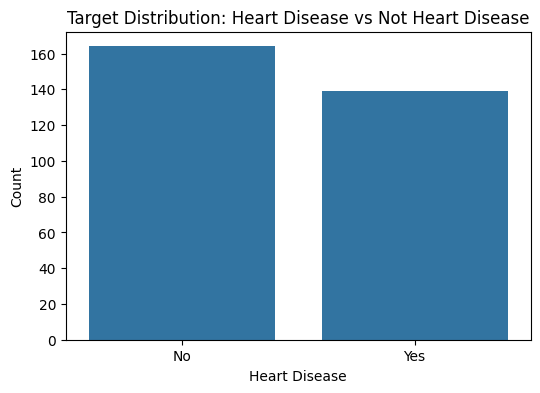

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="num")
plt.title("Target Distribution: Heart Disease vs Not Heart Disease")
plt.xlabel("Heart Disease")
plt.ylabel("Count")
plt.show()

##Overall distributions of all input features

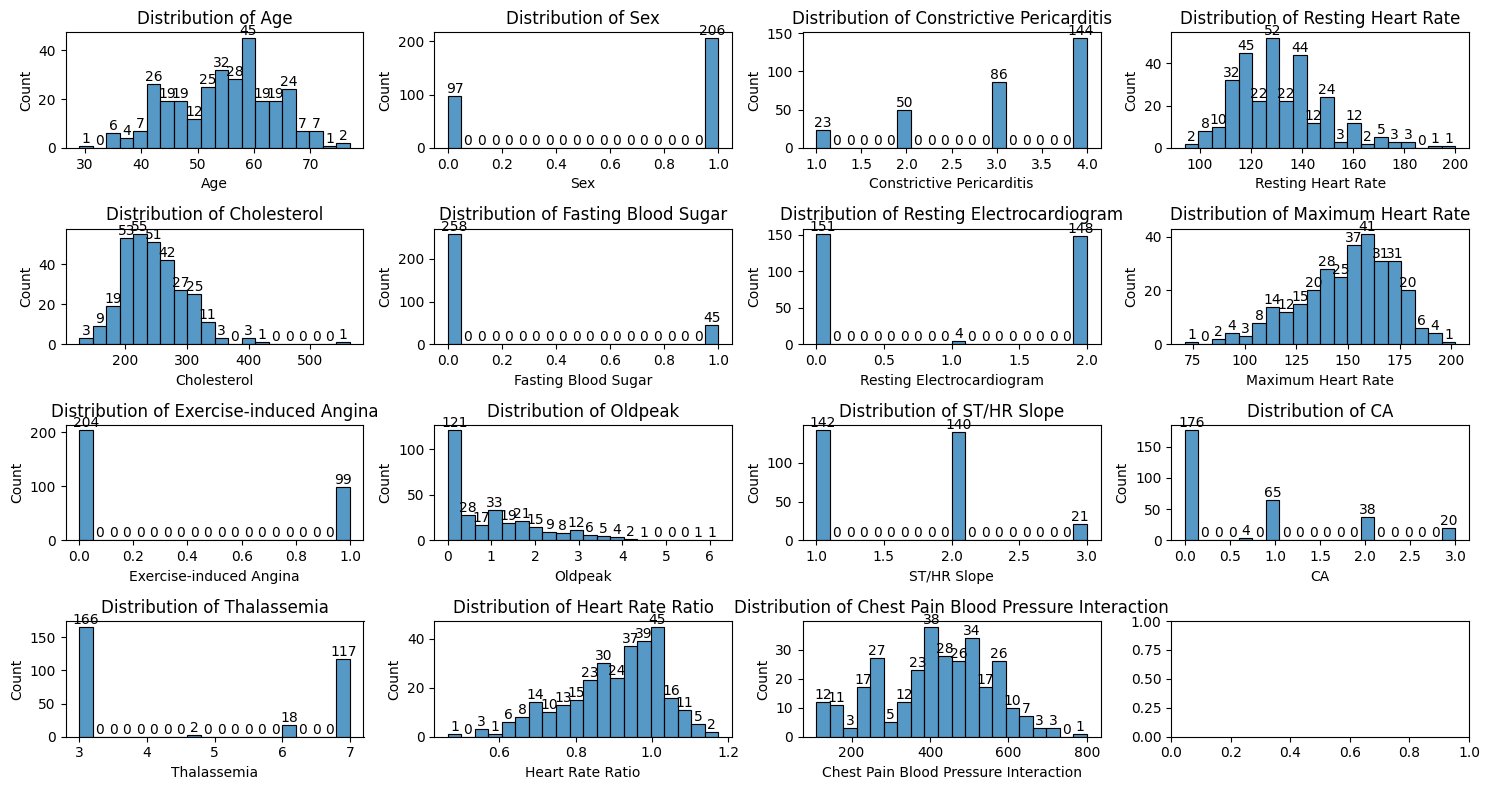

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(15, 8))
axes = axes.flatten()

for i in range(len(inputs)):
    sns.histplot(
        data=df,
        x=inputs[i],
        bins=20,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {feature_titles[i]}")
    axes[i].set_xlabel(feature_xlabels[i])
    axes[i].set_ylabel("Count")
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.0f')


plt.tight_layout()
plt.show()

## Input feature distributions by Heart Disease

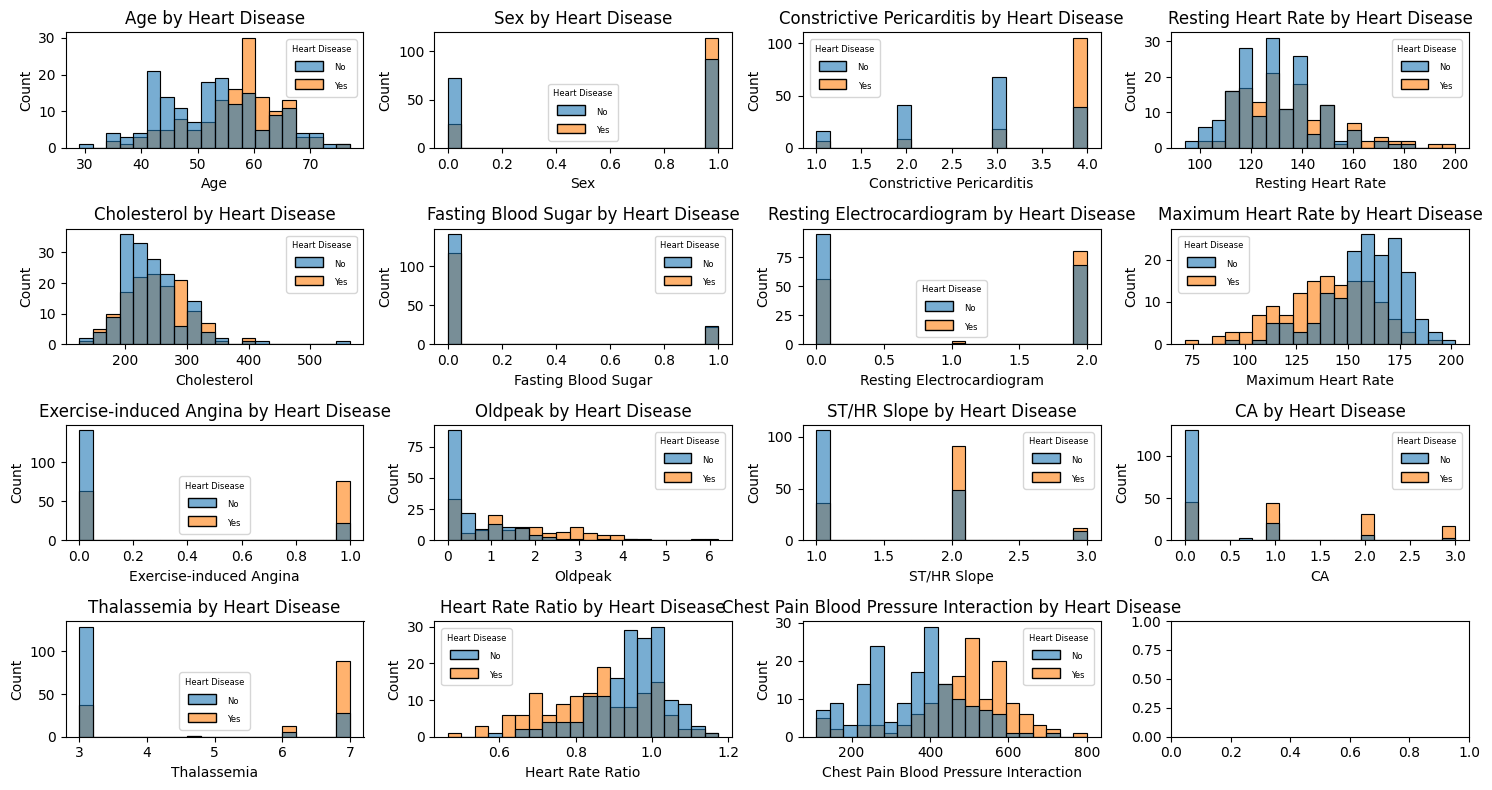

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(15, 8))
axes = axes.flatten()

for i in range(len(inputs)):
    sns.histplot(
        data=df,
        x=inputs[i],
        hue="num",
        bins=20,
        alpha=0.6,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature_titles[i]} by Heart Disease")
    axes[i].set_xlabel(feature_xlabels[i])
    axes[i].set_ylabel("Count")


    if axes[i].legend_:
        axes[i].legend_.set_title("Heart Disease", prop={"size": 6})
        for text in axes[i].legend_.get_texts():
            text.set_fontsize(6)




plt.tight_layout()
plt.show()

##Box plot of features by target class

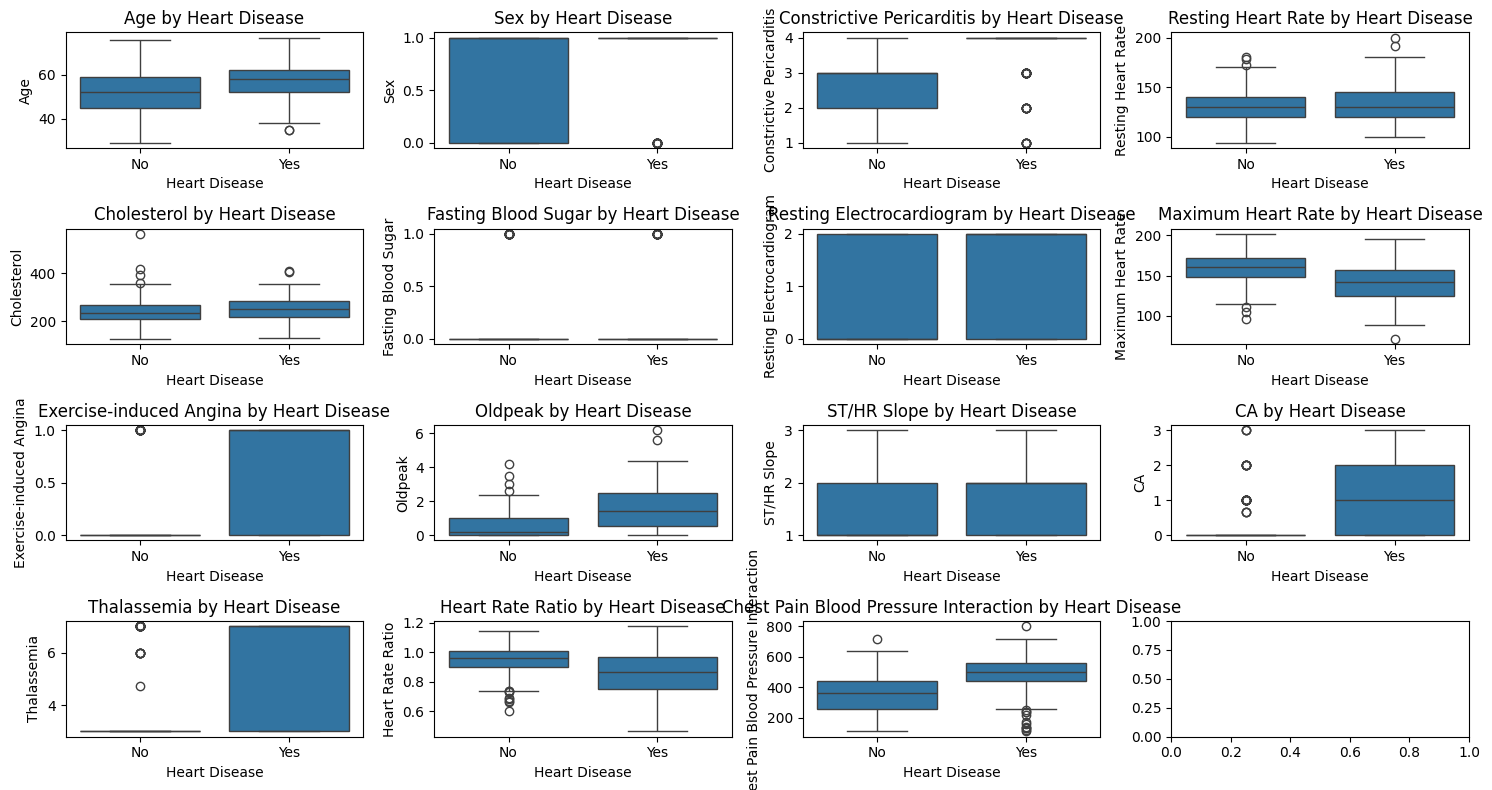

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(15, 8))
axes = axes.flatten()

for i in range(len(inputs)):
    sns.boxplot(
        data=df,
        x="num",
        y=inputs[i],
        ax=axes[i]
    )
    axes[i].set_title(f"{feature_titles[i]} by Heart Disease")
    axes[i].set_xlabel("Heart Disease")
    axes[i].set_ylabel(feature_xlabels[i])



plt.tight_layout()
plt.show()

Box Plot Resting Heart Rate by Heart Disease

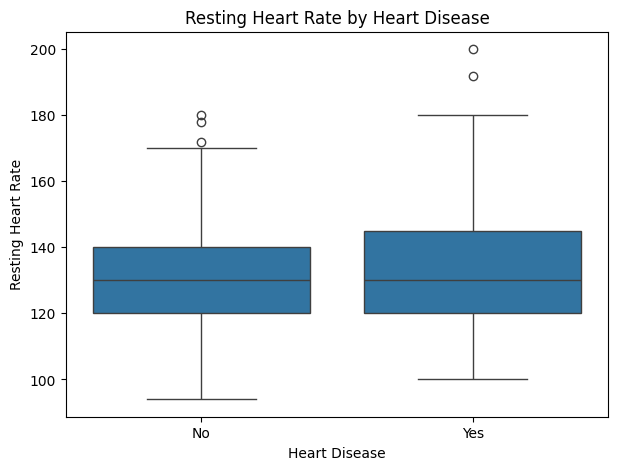

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="num",
    y="trestbps"
)
plt.title("Resting Heart Rate by Heart Disease")
plt.xlabel("Heart Disease")
plt.ylabel("Resting Heart Rate")
plt.show()

Box plot of Age by Heart Disease

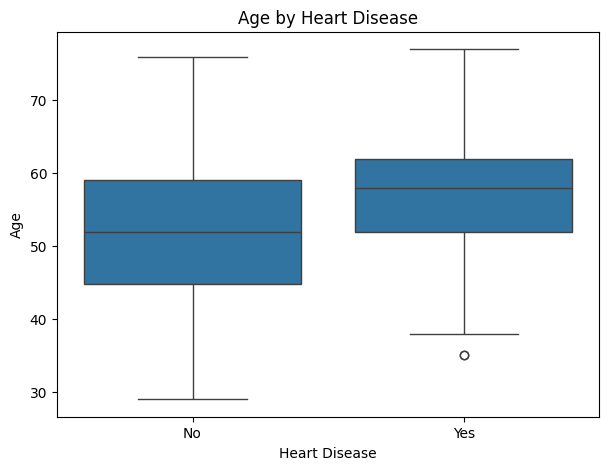

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="num",
    y="age"
)
plt.title("Age by Heart Disease")
plt.xlabel("Heart Disease")
plt.ylabel("Age")
plt.show()

##Age vs cholesterol


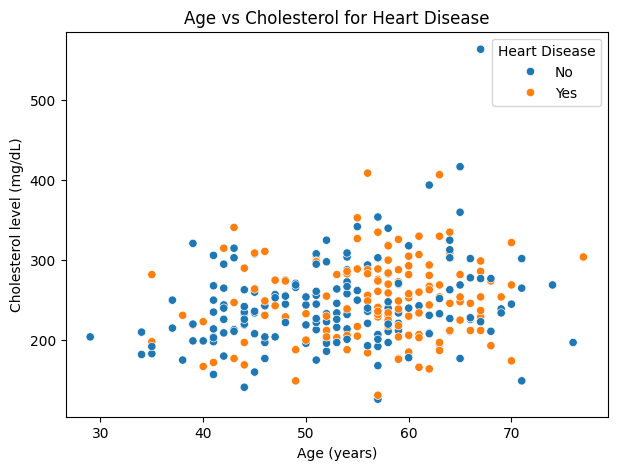

In [ ]:

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="chol",
    hue="num"
)

plt.legend(title="Heart Disease")
plt.title("Age vs Cholesterol for Heart Disease")
plt.xlabel("Age (years)")
plt.ylabel("Cholesterol level (mg/dL)")
plt.show()

##Scatterplots for all features

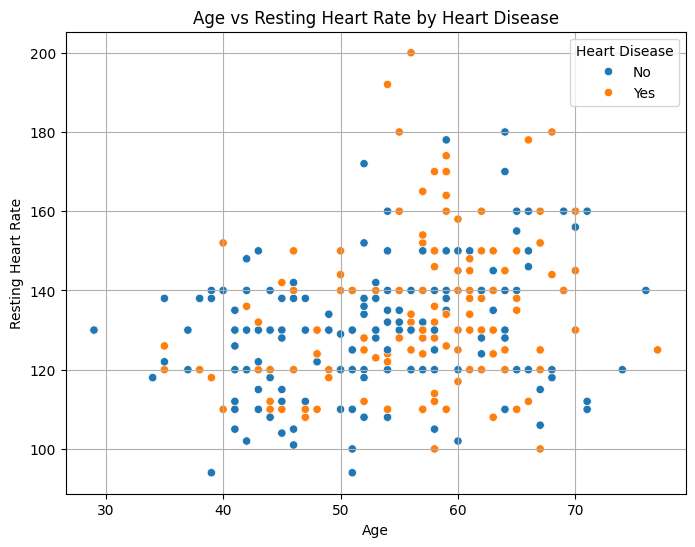

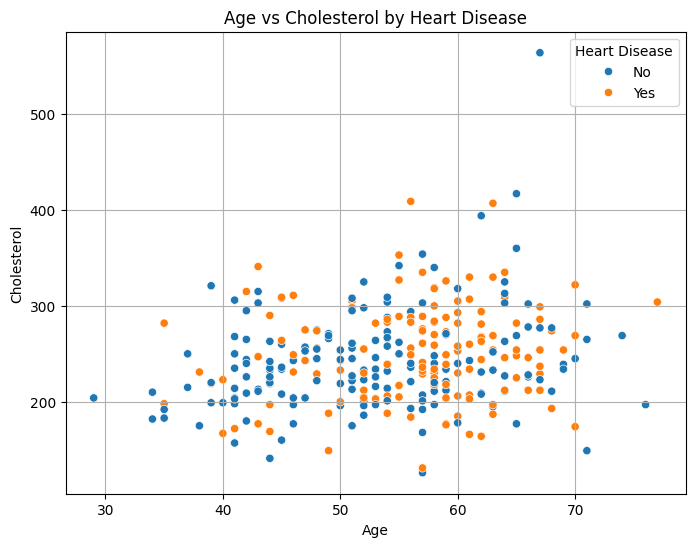

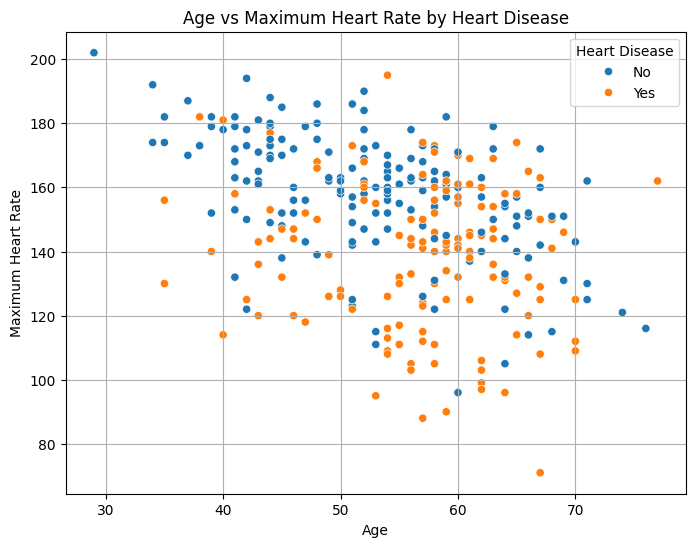

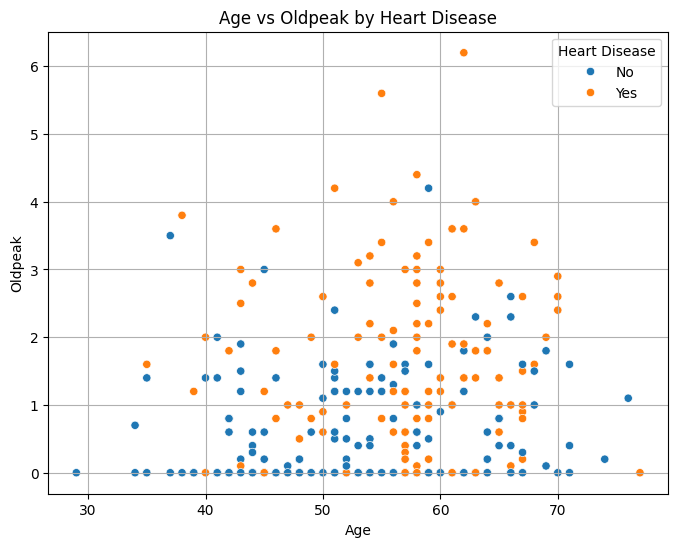

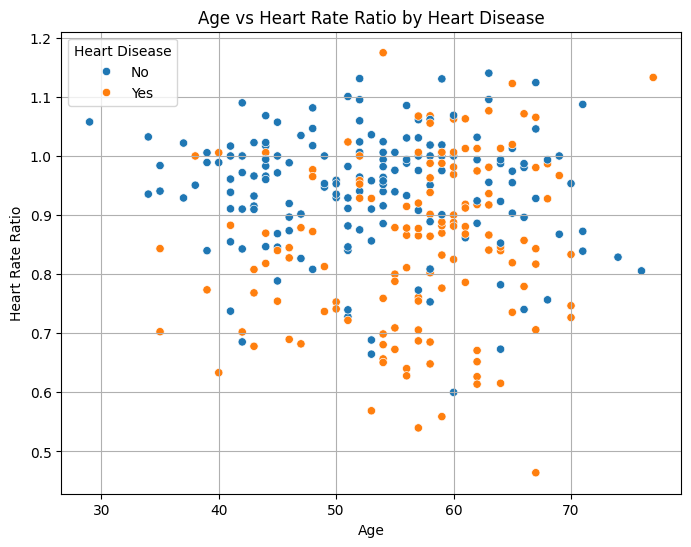

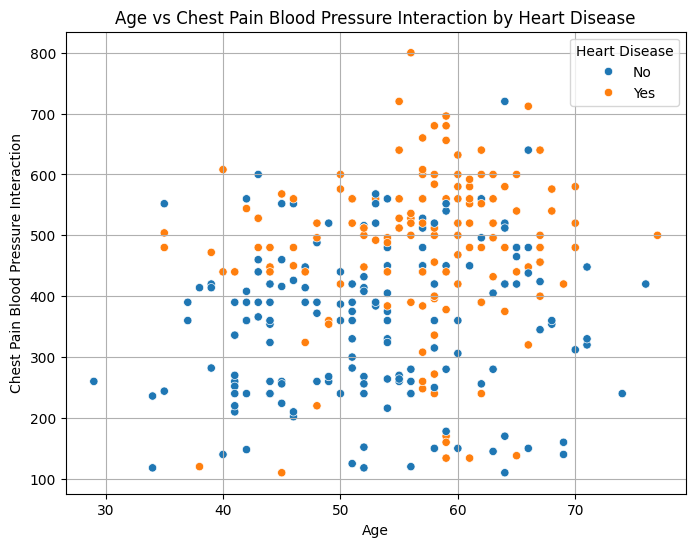

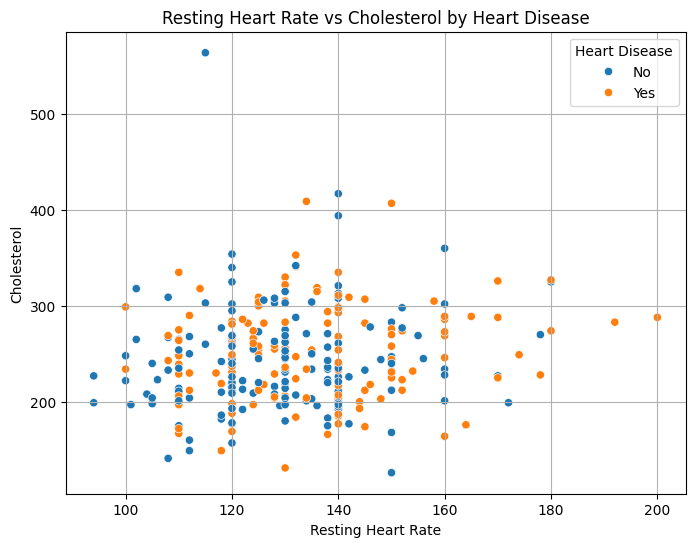

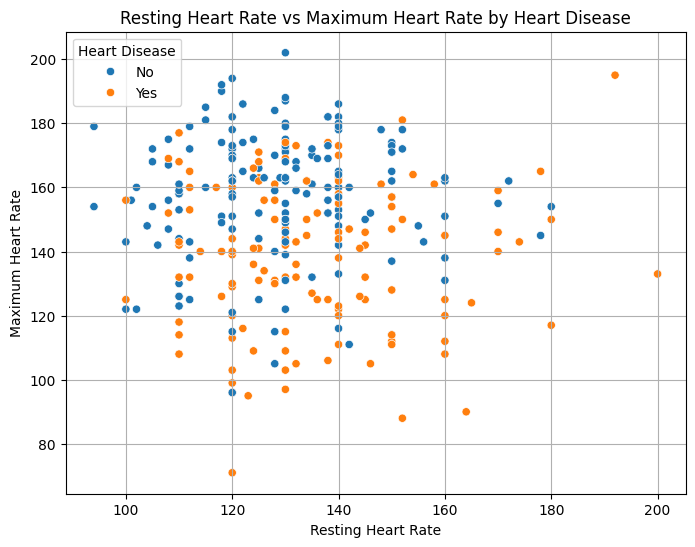

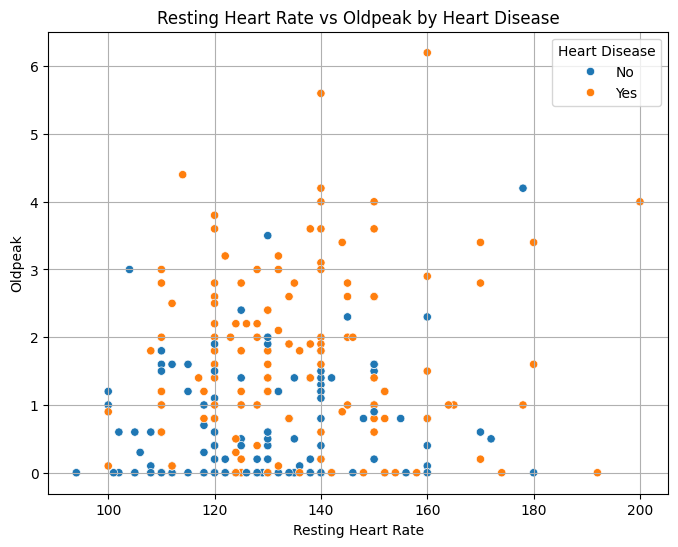

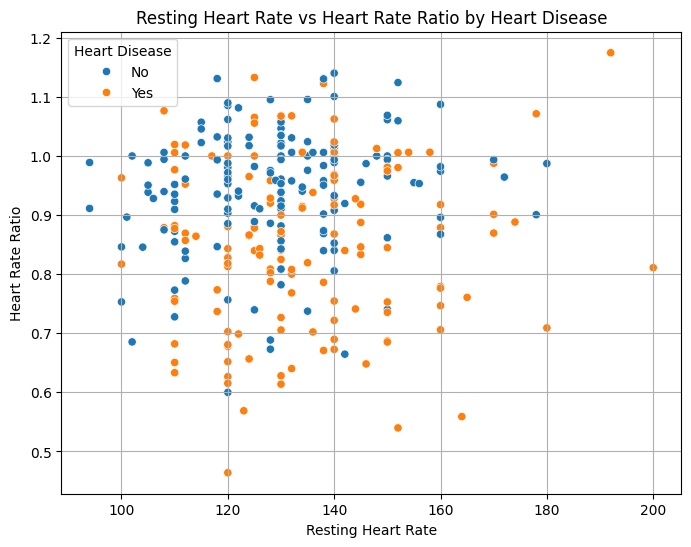

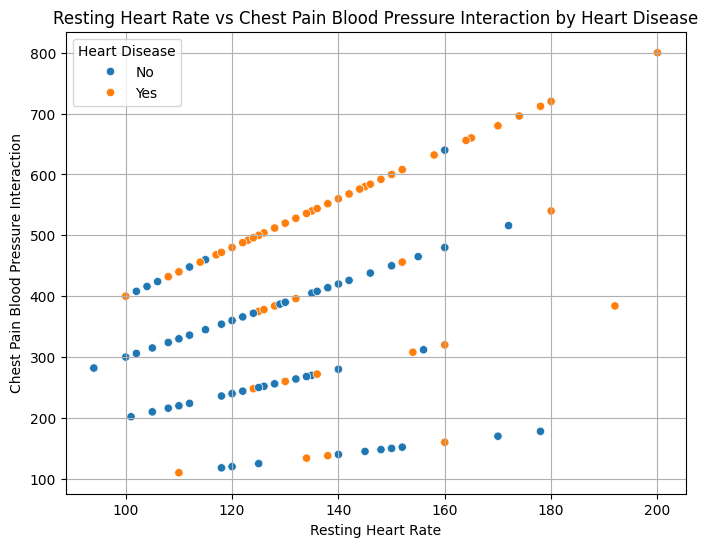

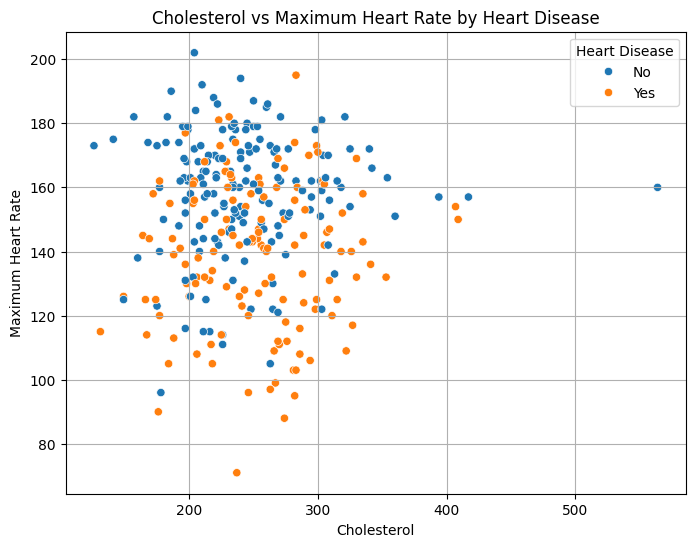

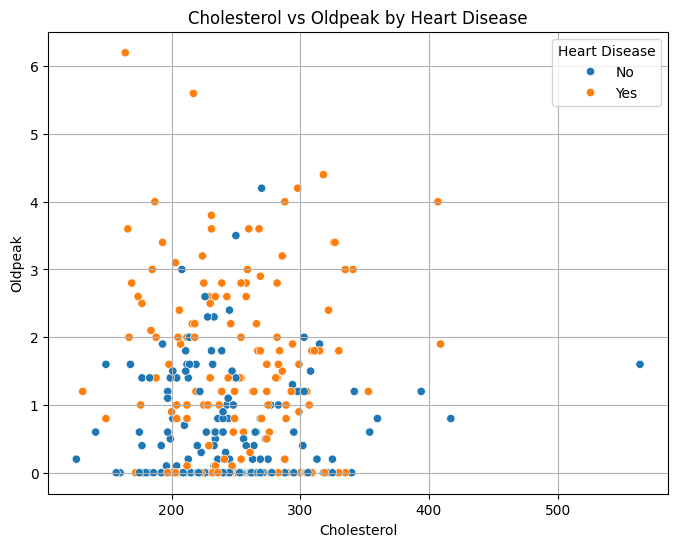

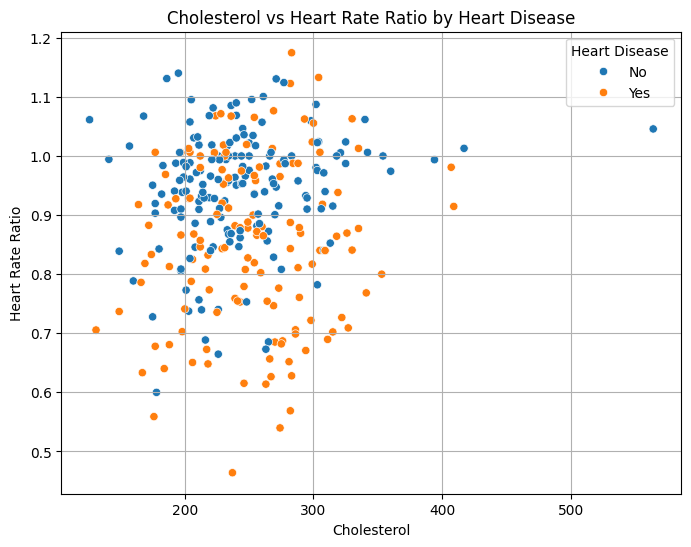

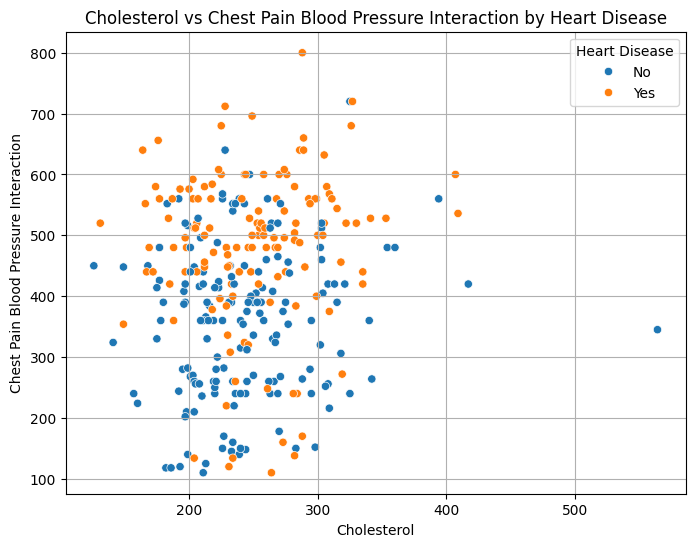

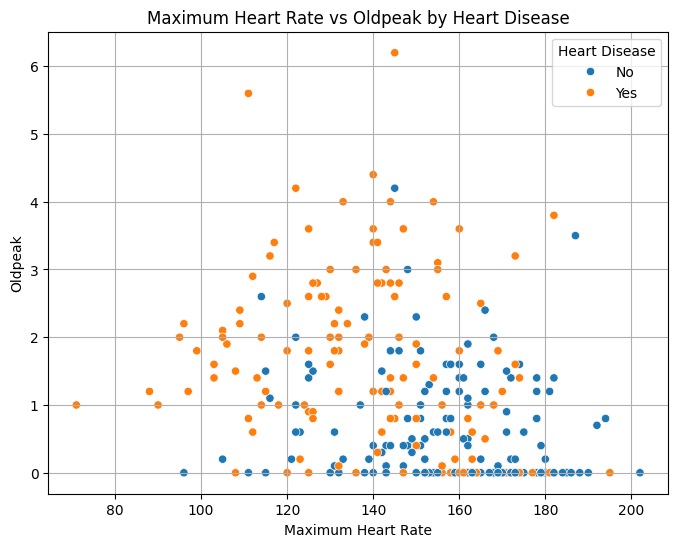

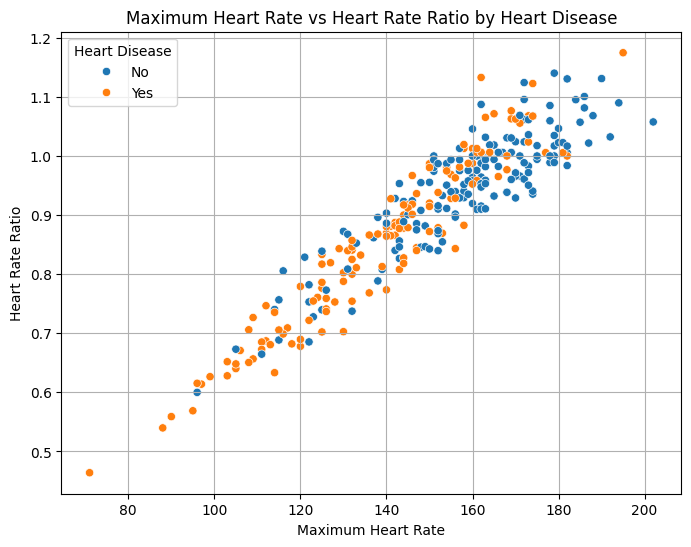

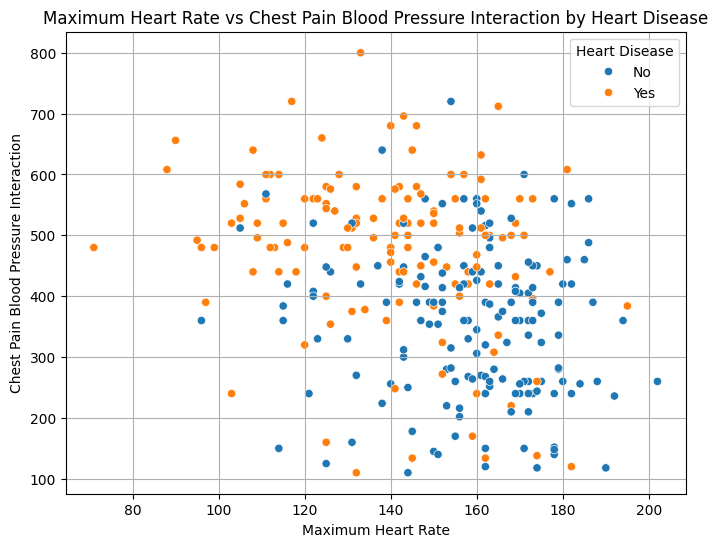

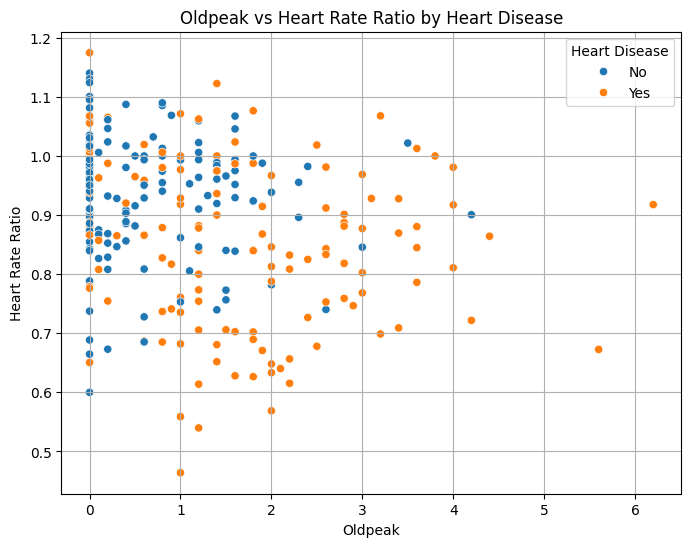

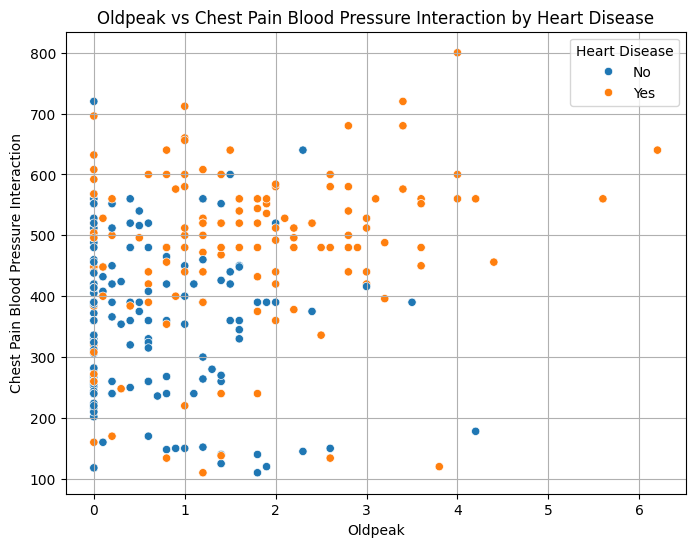

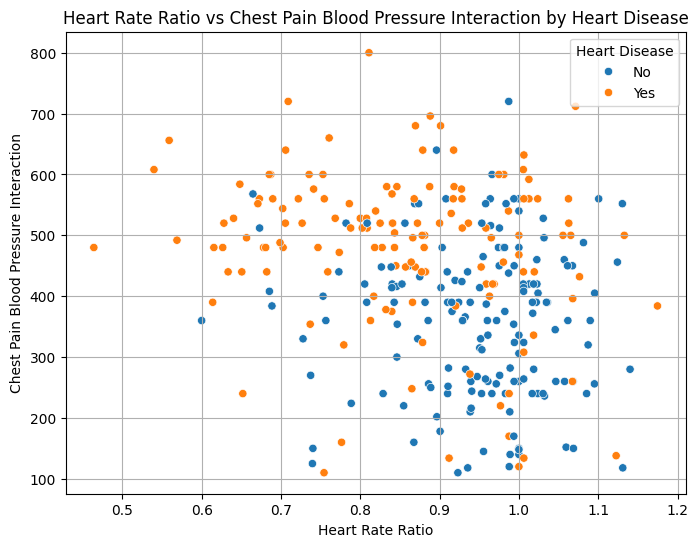

In [ ]:
import itertools

# Create a mapping from feature name to feature title for better plot labels
feature_name_to_title = dict(zip(inputs, feature_titles))

numerical_features_for_scatter = []
for col in inputs:
    if df[col].dtype in ['int64', 'float64'] and df[col].nunique() > 5: # Select numerical features with more than 5 unique values
        numerical_features_for_scatter.append(col)

# Iterate through all unique pairs of numerical features
for x_feature, y_feature in itertools.combinations(numerical_features_for_scatter, 2):
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=df,
        x=x_feature,
        y=y_feature,
        hue="num" # Color code by the target 'num'
    )
    # Set title and labels using the feature_name_to_title mapping
    plt.title(f"{feature_name_to_title.get(x_feature, x_feature)} vs {feature_name_to_title.get(y_feature, y_feature)} by Heart Disease")
    plt.xlabel(feature_name_to_title.get(x_feature, x_feature))
    plt.ylabel(feature_name_to_title.get(y_feature, y_feature))
    plt.legend(title="Heart Disease")
    plt.grid(True)
    plt.show()

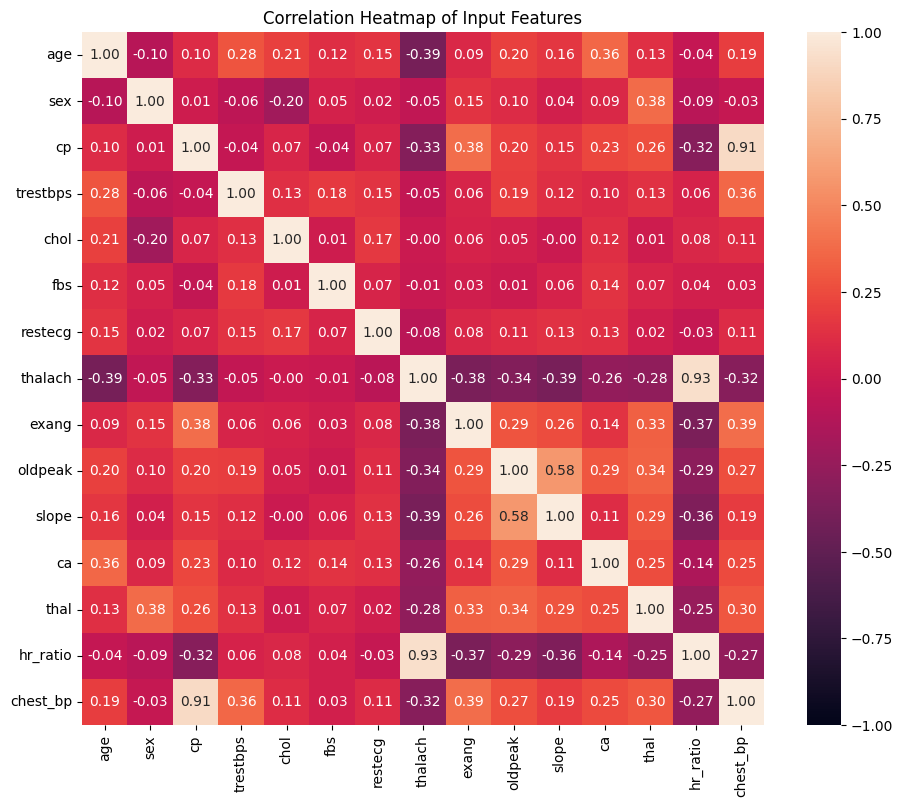

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[inputs].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap of Input Features")
plt.show()

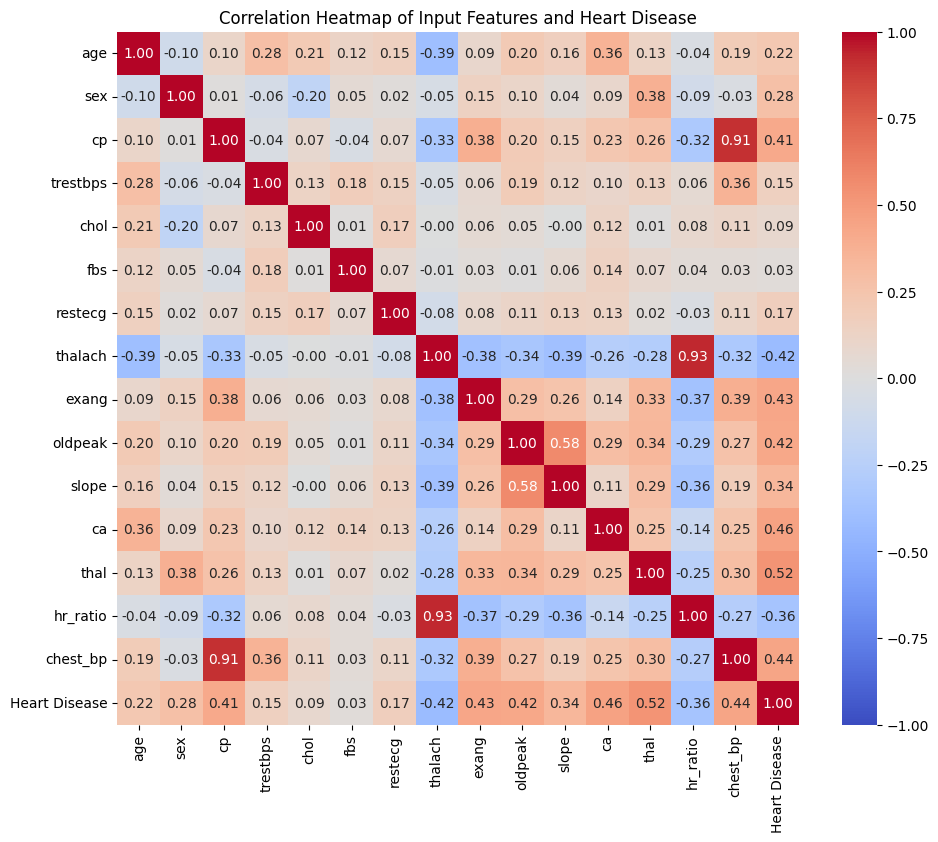

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[inputs + ["Heart Disease"]].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Input Features and Heart Disease")
plt.show()

##Graphs of individual features against each other

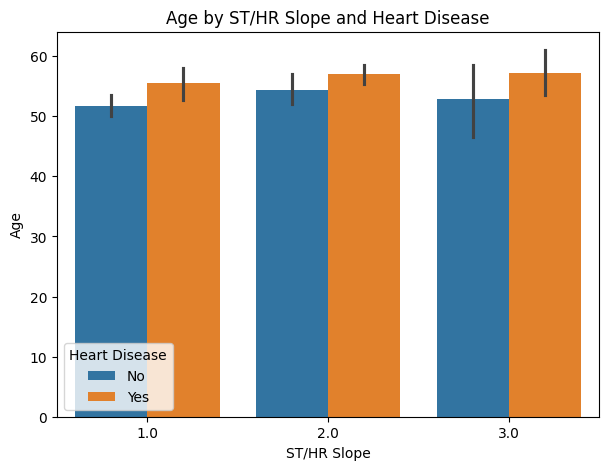

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="slope",
    y="age",
    hue="num"
)

plt.legend(title="Heart Disease")
plt.title("Age by ST/HR Slope and Heart Disease")
plt.xlabel("ST/HR Slope")
plt.ylabel("Age")
plt.show()

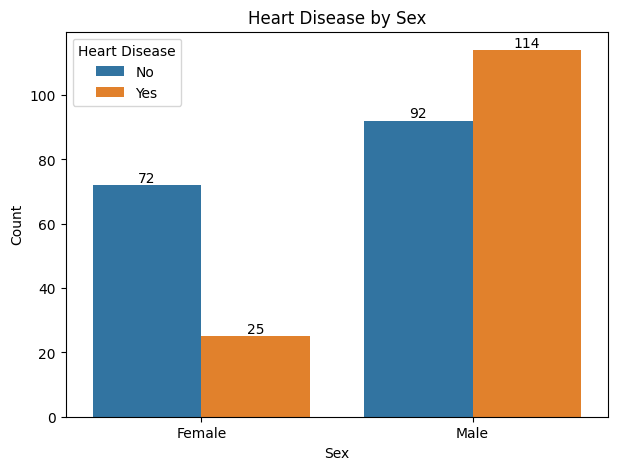

In [ ]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="sex",
    hue="num"
)

plt.legend(title="Heart Disease")
plt.title("Heart Disease by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")

plt.xticks(ticks=[0, 1], labels=['Female', 'Male'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.show()

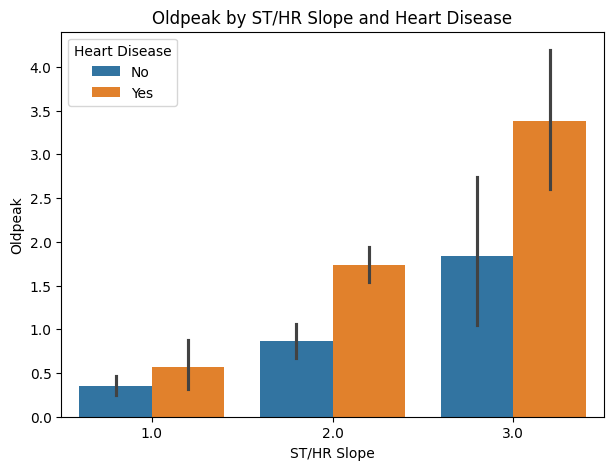

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="slope",
    y="oldpeak",
    hue="num"
)

plt.legend(title="Heart Disease")
plt.title("Oldpeak by ST/HR Slope and Heart Disease")
plt.xlabel("ST/HR Slope")
plt.ylabel("Oldpeak")
plt.show()

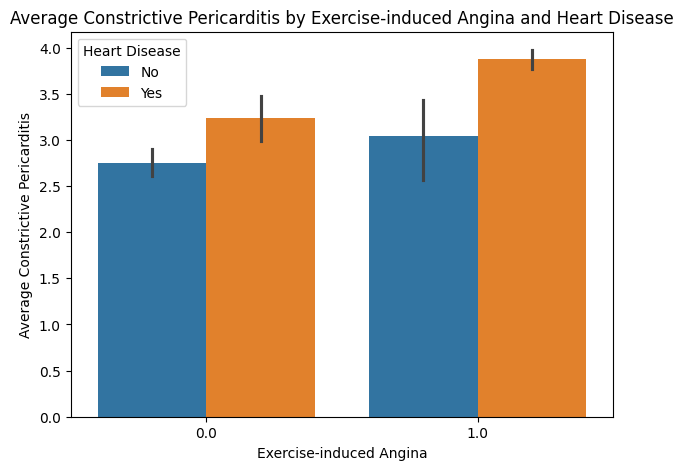

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="exang",
    y="cp",
    hue="num"
)

plt.legend(title="Heart Disease")
plt.title("Average Constrictive Pericarditis by Exercise-induced Angina and Heart Disease")
plt.xlabel("Exercise-induced Angina")
plt.ylabel("Average Constrictive Pericarditis")
plt.show()

##Prepare x and y for the Models

Random Forest Model 1, Logistic Regression Model 1

In [ ]:
numeric_model_features = [
"age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca"
]

categorical_model_features = ["cp", "restecg", "slope", "thal"]

X_raw = df[numeric_model_features + categorical_model_features]
y = df["Heart Disease"]

print("Input data:")
display(X_raw.head())

print("Target values:")
display(y.head(20))

Input data:


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp,restecg,slope,thal
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,1.0,2.0,3.0,6.0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,4.0,2.0,2.0,3.0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,4.0,2.0,2.0,7.0
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,3.0,0.0,3.0,3.0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,2.0,2.0,1.0,3.0


Target values:


,Heart Disease
0,0
1,1
2,1
3,0
4,0
5,0
6,1
7,0
8,1
9,1


Random Forest Model 2, Logistic Regression Model 2

In [ ]:
numeric_model_features_hr = [
"age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca", "hr_ratio"
]

categorical_model_features = ["cp", "restecg", "slope", "thal"]

X_raw_hr = df[numeric_model_features_hr + categorical_model_features]
y_hr = df["Heart Disease"]

print("Input data:")
display(X_raw_hr.head())

print("Target values:")
display(y_hr.head(20))

Input data:


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,hr_ratio,cp,restecg,slope,thal
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0.955414,1.0,2.0,3.0,6.0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,0.705882,4.0,2.0,2.0,3.0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,0.843137,4.0,2.0,2.0,7.0
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,1.021858,3.0,0.0,3.0,3.0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0.960894,2.0,2.0,1.0,3.0


Target values:


,Heart Disease
0,0
1,1
2,1
3,0
4,0
5,0
6,1
7,0
8,1
9,1


Random Forest Model 3, Logistic Regression Model 3

In [ ]:
numeric_model_features_chest_bp = [
"age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca", "chest_bp"
]

categorical_model_features = ["cp", "restecg", "slope", "thal"]

X_raw_chest_bp = df[numeric_model_features_chest_bp + categorical_model_features]
y_chest_bp = df["Heart Disease"]

print("Input data:")
display(X_raw_chest_bp.head())

print("Target values:")
display(y_chest_bp.head(20))

Input data:


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,chest_bp,cp,restecg,slope,thal
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,145.0,1.0,2.0,3.0,6.0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,640.0,4.0,2.0,2.0,3.0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,480.0,4.0,2.0,2.0,7.0
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,390.0,3.0,0.0,3.0,3.0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,260.0,2.0,2.0,1.0,3.0


Target values:


,Heart Disease
0,0
1,1
2,1
3,0
4,0
5,0
6,1
7,0
8,1
9,1


In [ ]:
numeric_model_features_thalach_bp = [
"age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca", "thalach_bp"
]

categorical_model_features = ["cp", "restecg", "slope", "thal"]

X_raw_thalach_bp = df[numeric_model_features_thalach_bp + categorical_model_features]
y_thalach_bp = df["Heart Disease"]

print("Input data:")
display(X_raw_thalach_bp.head())

print("Target values:")
display(y_thalach_bp.head(20))

Input data:


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,thalach_bp,cp,restecg,slope,thal
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,1.034483,1.0,2.0,3.0,6.0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,0.675000,4.0,2.0,2.0,3.0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1.075000,4.0,2.0,2.0,7.0
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,1.438462,3.0,0.0,3.0,3.0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,1.323077,2.0,2.0,1.0,3.0


Target values:


,Heart Disease
0,0
1,1
2,1
3,0
4,0
5,0
6,1
7,0
8,1
9,1


##One-hot encoding

Random Forest Model 1, Logistic Regression Model 1



In [ ]:
X = pd.get_dummies(
    X_raw,
    columns= ["cp", "restecg", "slope", "thal"],
    drop_first=True
)

X.head()



,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_4.73421926910299,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,False,False,False,False,True,False,True,False,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,False,False,True,False,True,True,False,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,False,False,True,False,True,True,False,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,False,True,False,False,False,False,True,False,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,True,False,False,False,True,False,False,False,False,False


In [ ]:
print("Number of input features:", X.shape[1])
print("Feature names:")
list(X.columns)

Number of input features: 19
Feature names:


['age',
 'sex',
 'trestbps',
 'chol',
 'fbs',
 'thalach',
 'exang',
 'oldpeak',
 'ca',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'restecg_1.0',
 'restecg_2.0',
 'slope_2.0',
 'slope_3.0',
 'thal_4.73421926910299',
 'thal_6.0',
 'thal_7.0']

Random Forest Model 2, Logistic Regression Model 2

In [ ]:
X_hr = pd.get_dummies(
    X_raw_hr,
    columns= ["cp", "restecg", "slope", "thal"],
    drop_first=True
)

X_hr.head()


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,hr_ratio,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_4.73421926910299,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0.955414,False,False,False,False,True,False,True,False,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,0.705882,False,False,True,False,True,True,False,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,0.843137,False,False,True,False,True,True,False,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,1.021858,False,True,False,False,False,False,True,False,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0.960894,True,False,False,False,True,False,False,False,False,False


In [ ]:
print("Number of input features:", X_hr.shape[1])
print("Feature names:")
list(X_hr.columns)

Number of input features: 20
Feature names:


['age',
 'sex',
 'trestbps',
 'chol',
 'fbs',
 'thalach',
 'exang',
 'oldpeak',
 'ca',
 'hr_ratio',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'restecg_1.0',
 'restecg_2.0',
 'slope_2.0',
 'slope_3.0',
 'thal_4.73421926910299',
 'thal_6.0',
 'thal_7.0']

Random Forest Model 3, Logistic Regression Model 4

In [ ]:
X_chest_bp = pd.get_dummies(
    X_raw_chest_bp,
    columns= ["cp", "restecg", "slope", "thal"],
    drop_first=True
)

X_chest_bp.head()


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,chest_bp,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_4.73421926910299,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,145.0,False,False,False,False,True,False,True,False,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,640.0,False,False,True,False,True,True,False,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,480.0,False,False,True,False,True,True,False,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,390.0,False,True,False,False,False,False,True,False,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,260.0,True,False,False,False,True,False,False,False,False,False


In [ ]:
print("Number of input features:", X_chest_bp.shape[1])
print("Feature names:")
list(X_chest_bp.columns)

Number of input features: 20
Feature names:


['age',
 'sex',
 'trestbps',
 'chol',
 'fbs',
 'thalach',
 'exang',
 'oldpeak',
 'ca',
 'chest_bp',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'restecg_1.0',
 'restecg_2.0',
 'slope_2.0',
 'slope_3.0',
 'thal_4.73421926910299',
 'thal_6.0',
 'thal_7.0']

Random Forest Model 4, Logistic Regression Model 4

In [ ]:
X_thalach_bp = pd.get_dummies(
    X_raw_thalach_bp,
    columns= ["cp", "restecg", "slope", "thal"],
    drop_first=True
)

X_thalach_bp.head()


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,thalach_bp,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_4.73421926910299,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,1.034483,False,False,False,False,True,False,True,False,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,0.675000,False,False,True,False,True,True,False,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1.075000,False,False,True,False,True,True,False,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,1.438462,False,True,False,False,False,False,True,False,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,1.323077,True,False,False,False,True,False,False,False,False,False


In [ ]:
print("Number of input features:", X_thalach_bp.shape[1])
print("Feature names:")
list(X_thalach_bp.columns)

Number of input features: 20
Feature names:


['age',
 'sex',
 'trestbps',
 'chol',
 'fbs',
 'thalach',
 'exang',
 'oldpeak',
 'ca',
 'thalach_bp',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'restecg_1.0',
 'restecg_2.0',
 'slope_2.0',
 'slope_3.0',
 'thal_4.73421926910299',
 'thal_6.0',
 'thal_7.0']

##Train-test split

Random Forest Model 1, Logistic Regression Model 1

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 242
Testing rows: 61


Random Forest Model 2, Logistic Regression Model 2

In [ ]:
X_train_hr, X_test_hr, y_train_hr, y_test_hr = train_test_split(
    X_hr,
    y_hr,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train_hr.shape[0])
print("Testing rows:", X_test_hr.shape[0])

Training rows: 242
Testing rows: 61


Random Forest Model 3, Logistic Regression Model 3

In [ ]:
X_train_chest_bp, X_test_chest_bp, y_train_chest_bp, y_test_chest_bp = train_test_split(
    X_chest_bp,
    y_chest_bp,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train_chest_bp.shape[0])
print("Testing rows:", X_test_chest_bp.shape[0])

Training rows: 242
Testing rows: 61


Random Forest Model 4, Logistic Regression Model 4

In [ ]:
X_train_thalach_bp, X_test_thalach_bp, y_train_thalach_bp, y_test_thalach_bp = train_test_split(
    X_thalach_bp,
    y_thalach_bp,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train_thalach_bp.shape[0])
print("Testing rows:", X_test_thalach_bp.shape[0])

Training rows: 242
Testing rows: 61


##Train the Models

Random Forest Model 1

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=2
)

rf_model.fit(X_train, y_train)


RandomForestClassifier(max_depth=2, n_estimators=200, random_state=42)

In [ ]:
rf_pred = rf_model.predict(X_test)

Random Forest Model 2

In [ ]:
rf2_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth = 3
)

rf2_model.fit(X_train_hr, y_train_hr)


RandomForestClassifier(max_depth=3, n_estimators=200, random_state=42)

In [ ]:
rf2_pred = rf2_model.predict(X_test_hr)

Random Forest Model 3

In [ ]:
rf3_model = RandomForestClassifier(
    n_estimators=175,
    random_state=42,
    max_depth = 4
)

rf3_model.fit(X_train_chest_bp, y_train_chest_bp)


RandomForestClassifier(max_depth=4, n_estimators=175, random_state=42)

In [ ]:
rf3_pred = rf3_model.predict(X_test_chest_bp)

Random Forest Model 4

In [ ]:
rf4_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    max_depth = 4
)

rf4_model.fit(X_train_thalach_bp, y_train_thalach_bp)


RandomForestClassifier(max_depth=4, n_estimators=300, random_state=42)

In [ ]:
rf4_pred = rf4_model.predict(X_test_thalach_bp)

Logistic Regression Model 1

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    random_state = 42,
    penalty="l1",
    solver="liblinear"

)
lr_model.fit(X_train, y_train)

LogisticRegression(penalty='l1', random_state=42, solver='liblinear')

In [ ]:
lr_pred = lr_model.predict(X_test)

Logistic Regression Model 2

In [ ]:
from sklearn.linear_model import LogisticRegression

lr2_model = LogisticRegression(
    random_state = 42,
    penalty="l1",
    solver="liblinear"
)
lr2_model.fit(X_train_hr, y_train_hr)

LogisticRegression(penalty='l1', random_state=42, solver='liblinear')

In [ ]:
lr2_pred = lr2_model.predict(X_test_hr)

Logistic Regression Model 3

In [ ]:
from sklearn.linear_model import LogisticRegression

lr3_model = LogisticRegression(
    random_state = 42,
    C = 0.1,

)
lr3_model.fit(X_train_chest_bp, y_train_chest_bp)

LogisticRegression(C=0.1, random_state=42)

In [ ]:
lr3_pred = lr3_model.predict(X_test_chest_bp)

Logistic Regression Model 4

In [ ]:
from sklearn.linear_model import LogisticRegression

lr4_model = LogisticRegression(
    random_state = 42,
    C = 10
)
lr4_model.fit(X_train_thalach_bp, y_train_thalach_bp)

LogisticRegression(C=10, random_state=42)

In [ ]:
lr4_pred = lr4_model.predict(X_test_thalach_bp)

##All Models Evaluation

Random Forest Model 1

In [ ]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-sc0ore"],
    "Score": [rf_accuracy, rf_precision, rf_recall, rf_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.934
1,Precision,0.900
2,Recall,0.964
3,F1-sc0ore,0.931


Random Forest Model 2

In [ ]:
rf2_accuracy = accuracy_score(y_test_hr, rf2_pred)
rf2_precision = precision_score(y_test_hr, rf2_pred)
rf2_recall = recall_score(y_test_hr, rf2_pred)
rf2_f1 = f1_score(y_test_hr, rf2_pred)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [rf2_accuracy, rf2_precision, rf2_recall, rf2_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.902
1,Precision,0.867
2,Recall,0.929
3,F1-score,0.897


Random Forest Model 3

In [ ]:
rf3_accuracy = accuracy_score(y_test_chest_bp, rf3_pred)
rf3_precision = precision_score(y_test_chest_bp, rf3_pred)
rf3_recall = recall_score(y_test_chest_bp, rf3_pred)
rf3_f1 = f1_score(y_test_chest_bp, rf3_pred)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [rf3_accuracy, rf3_precision, rf3_recall, rf3_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.918
1,Precision,0.871
2,Recall,0.964
3,F1-score,0.915


Random Forest Model 4

In [ ]:
rf4_accuracy = accuracy_score(y_test_thalach_bp, rf4_pred)
rf4_precision = precision_score(y_test_thalach_bp, rf4_pred)
rf4_recall = recall_score(y_test_thalach_bp, rf4_pred)
rf4_f1 = f1_score(y_test_thalach_bp, rf4_pred)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [rf4_accuracy, rf4_precision, rf4_recall, rf4_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.902
1,Precision,0.844
2,Recall,0.964
3,F1-score,0.900


Logistic Regression Model 1

In [ ]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

metrics_df = pd.DataFrame({
   "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [lr_accuracy, lr_precision, lr_recall, lr_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.852
1,Precision,0.828
2,Recall,0.857
3,F1-score,0.842


Logistic Regression Model 2

In [ ]:
lr2_accuracy = accuracy_score(y_test_hr, lr2_pred)
lr2_precision = precision_score(y_test_hr, lr2_pred)
lr2_recall = recall_score(y_test_hr, lr2_pred)
lr2_f1 = f1_score(y_test_hr, lr2_pred)

metrics_df = pd.DataFrame({
   "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [lr2_accuracy, lr2_precision, lr2_recall, lr2_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.869
1,Precision,0.833
2,Recall,0.893
3,F1-score,0.862


Logistic Regression Model 3

In [ ]:
lr3_accuracy = accuracy_score(y_test_chest_bp, lr3_pred)
lr3_precision = precision_score(y_test_chest_bp, lr3_pred)
lr3_recall = recall_score(y_test_chest_bp, lr3_pred)
lr3_f1 = f1_score(y_test_chest_bp, lr3_pred)

metrics_df = pd.DataFrame({
   "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [lr3_accuracy, lr3_precision, lr3_recall, lr3_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.918
1,Precision,0.871
2,Recall,0.964
3,F1-score,0.915


Logistic Regression Model 4

In [ ]:
lr4_accuracy = accuracy_score(y_test_thalach_bp, lr4_pred)
lr4_precision = precision_score(y_test_thalach_bp, lr4_pred)
lr4_recall = recall_score(y_test_thalach_bp, lr4_pred)
lr4_f1 = f1_score(y_test_thalach_bp, lr4_pred)

metrics_df = pd.DataFrame({
   "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [lr4_accuracy, lr4_precision, lr4_recall, lr4_f1]
})

metrics_df["Score"] = metrics_df["Score"].round(3)
metrics_df

,Metric,Score
0,Accuracy,0.869
1,Precision,0.833
2,Recall,0.893
3,F1-score,0.862


##Actual vs Predicted Test Cases for Random Forest Model

Shows model confidence, probability, and prediction result

Random Forest Model 1

In [ ]:
# Create a table that compares the test features, actual labels, and predicted labels

rf_prediction_results = X_test.copy().reset_index(drop=True)

# Add the actual and predicted y-values
rf_prediction_results["Actual_y"] = y_test.reset_index(drop=True)
rf_prediction_results["Predicted_y"] = rf_pred

# Add the model's probability for the Adelie class
heart_disease_class_index = list(rf_model.classes_).index(1)
rf_prediction_results["Probability_Heart_Disease"] = rf_model.predict_proba(X_test)[:, heart_disease_class_index]
rf_prediction_results["Probability_Heart_Disease"] = rf_prediction_results["Probability_Heart_Disease"].round(3)

# Convert 0 and 1 into readable class names
class_names = {
    0: "No Heart Disease",
    1: "Has Heart Disease"
}

rf_prediction_results["Actual_class"] = rf_prediction_results["Actual_y"].map(class_names)
rf_prediction_results["Predicted_class"] = rf_prediction_results["Predicted_y"].map(class_names)

# Check whether each prediction was correct
rf_prediction_results["Prediction_result"] = np.where(
    rf_prediction_results["Actual_y"] == rf_prediction_results["Predicted_y"],
    "Correct",
    "Wrong"
)

# Model confidence means the probability assigned to the class the model predicted.
# If the model predicted Adelie, confidence = Probability_Heart_Disease.
# If the model predicted Not Adelie, confidence = 1 - Probability_Heart_Disease.
rf_prediction_results["Model_confidence"] = np.where(
    rf_prediction_results["Predicted_y"] == 1,
    rf_prediction_results["Probability_Heart_Disease"],
    1 - rf_prediction_results["Probability_Heart_Disease"]
)
rf_prediction_results["Model_confidence"] = rf_prediction_results["Model_confidence"].round(3)

# Choose the columns we want to display
_rf_feature_columns_to_show = list(X_test.columns)
_rf_columns_to_show = _rf_feature_columns_to_show + [
    "Actual_y",
    "Predicted_y",
    "Actual_class",
    "Predicted_class",
    "Probability_Heart_Disease",
    "Model_confidence",
    "Prediction_result"
]

rf_prediction_results[_rf_columns_to_show].head(10)

,age,sex,trestbps,chol,fbs,exang,oldpeak,ca,restecg_1.0,restecg_2.0,...,thal_4.73421926910299,thal_6.0,thal_7.0,Actual_y,Predicted_y,Actual_class,Predicted_class,Probability_Heart_Disease,Model_confidence,Prediction_result
0,59.0,1.0,138.0,271.0,0.0,0.0,0.0,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.323,0.677,Correct
1,66.0,1.0,160.0,228.0,0.0,0.0,2.3,0.0,False,True,...,False,True,False,0,0,No Heart Disease,No Heart Disease,0.405,0.595,Correct
2,51.0,0.0,130.0,256.0,0.0,0.0,0.5,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.215,0.785,Correct
3,34.0,1.0,118.0,182.0,0.0,0.0,0.0,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.254,0.746,Correct
4,54.0,1.0,150.0,232.0,0.0,0.0,1.6,0.0,False,True,...,False,False,True,0,0,No Heart Disease,No Heart Disease,0.499,0.501,Correct
5,60.0,0.0,120.0,178.0,1.0,0.0,0.0,0.0,False,False,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.236,0.764,Correct
6,63.0,0.0,140.0,195.0,0.0,0.0,0.0,2.0,False,False,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.385,0.615,Correct
7,74.0,0.0,120.0,269.0,0.0,1.0,0.2,1.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.466,0.534,Correct
8,35.0,1.0,126.0,282.0,0.0,1.0,0.0,0.0,False,True,...,False,False,True,1,1,Has Heart Disease,Has Heart Disease,0.524,0.524,Correct
9,45.0,0.0,138.0,236.0,0.0,1.0,0.2,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.369,0.631,Correct


Random Forest Model 2

In [ ]:
# Create a table that compares the test features, actual labels, and predicted labels

rf2_prediction_results = X_test_hr.copy().reset_index(drop=True)

# Add the actual and predicted y-values
rf2_prediction_results["Actual_y"] = y_test_hr.reset_index(drop=True)
rf2_prediction_results["Predicted_y"] = rf2_pred

# Add the model's probability for the Adelie class
heart_disease_class_index = list(rf2_model.classes_).index(1)
rf2_prediction_results["Probability_Heart_Disease"] = rf2_model.predict_proba(X_test_hr)[:, heart_disease_class_index]
rf2_prediction_results["Probability_Heart_Disease"] = rf2_prediction_results["Probability_Heart_Disease"].round(3)

# Convert 0 and 1 into readable class names
class_names = {
    0: "No Heart Disease",
    1: "Has Heart Disease"
}

rf2_prediction_results["Actual_class"] = rf2_prediction_results["Actual_y"].map(class_names)
rf2_prediction_results["Predicted_class"] = rf2_prediction_results["Predicted_y"].map(class_names)

# Check whether each prediction was correct
rf2_prediction_results["Prediction_result"] = np.where(
    rf2_prediction_results["Actual_y"] == rf2_prediction_results["Predicted_y"],
    "Correct",
    "Wrong"
)

# Model confidence means the probability assigned to the class the model predicted.
# If the model predicted Adelie, confidence = Probability_Heart_Disease.
# If the model predicted Not Adelie, confidence = 1 - Probability_Heart_Disease.
rf2_prediction_results["Model_confidence"] = np.where(
    rf2_prediction_results["Predicted_y"] == 1,
    rf2_prediction_results["Probability_Heart_Disease"],
    1 - rf2_prediction_results["Probability_Heart_Disease"]
)
rf2_prediction_results["Model_confidence"] = rf2_prediction_results["Model_confidence"].round(3)

# Choose the columns we want to display
_rf2_feature_columns_to_show = list(X_test_hr.columns)
_rf2_columns_to_show = _rf2_feature_columns_to_show + [
    "Actual_y",
    "Predicted_y",
    "Actual_class",
    "Predicted_class",
    "Probability_Heart_Disease",
    "Model_confidence",
    "Prediction_result"
]

rf2_prediction_results[_rf2_columns_to_show].head(10)

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,hr_ratio,...,thal_4.73421926910299,thal_6.0,thal_7.0,Actual_y,Predicted_y,Actual_class,Predicted_class,Probability_Heart_Disease,Model_confidence,Prediction_result
0,59.0,1.0,138.0,271.0,0.0,182.0,0.0,0.0,0.0,1.130435,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.304,0.696,Correct
1,66.0,1.0,160.0,228.0,0.0,138.0,0.0,2.3,0.0,0.896104,...,False,True,False,0,0,No Heart Disease,No Heart Disease,0.499,0.501,Correct
2,51.0,0.0,130.0,256.0,0.0,149.0,0.0,0.5,0.0,0.881657,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.194,0.806,Correct
3,34.0,1.0,118.0,182.0,0.0,174.0,0.0,0.0,0.0,0.935484,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.133,0.867,Correct
4,54.0,1.0,150.0,232.0,0.0,165.0,0.0,1.6,0.0,0.993976,...,False,False,True,0,0,No Heart Disease,No Heart Disease,0.348,0.652,Correct
5,60.0,0.0,120.0,178.0,1.0,96.0,0.0,0.0,0.0,0.600000,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.338,0.662,Correct
6,63.0,0.0,140.0,195.0,0.0,179.0,0.0,0.0,2.0,1.140127,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.322,0.678,Correct
7,74.0,0.0,120.0,269.0,0.0,121.0,1.0,0.2,1.0,0.828767,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.437,0.563,Correct
8,35.0,1.0,126.0,282.0,0.0,156.0,1.0,0.0,0.0,0.843243,...,False,False,True,1,1,Has Heart Disease,Has Heart Disease,0.596,0.596,Correct
9,45.0,0.0,138.0,236.0,0.0,152.0,1.0,0.2,0.0,0.868571,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.382,0.618,Correct


Logistic Regression Model

In [ ]:
# Create a table that compares the test features, actual labels, and predicted labels

lr_prediction_results = X_test.copy().reset_index(drop=True)

# Add the actual and predicted y-values
lr_prediction_results["Actual_y"] = y_test.reset_index(drop=True)
lr_prediction_results["Predicted_y"] = lr_pred

# Add the model's probability for the Adelie class
heart_disease_class_index = list(lr_model.classes_).index(1)
lr_prediction_results["Probability_Heart_Disease"] = lr_model.predict_proba(X_test)[:, heart_disease_class_index]
lr_prediction_results["Probability_Heart_Disease"] = lr_prediction_results["Probability_Heart_Disease"].round(3)

# Convert 0 and 1 into readable class names
class_names = {
    0: "No Heart Disease",
    1: "Has Heart Disease"
}

lr_prediction_results["Actual_class"] = lr_prediction_results["Actual_y"].map(class_names)
lr_prediction_results["Predicted_class"] = lr_prediction_results["Predicted_y"].map(class_names)

# Check whether each prediction was correct
lr_prediction_results["Prediction_result"] = np.where(
    lr_prediction_results["Actual_y"] == lr_prediction_results["Predicted_y"],
    "Correct",
    "Wrong"
)

# Model confidence means the probability assigned to the class the model predicted.
# If the model predicted Adelie, confidence = Probability_Heart_Disease.
# If the model predicted Not Adelie, confidence = 1 - Probability_Heart_Disease.
lr_prediction_results["Model_confidence"] = np.where(
    lr_prediction_results["Predicted_y"] == 1,
    lr_prediction_results["Probability_Heart_Disease"],
    1 - lr_prediction_results["Probability_Heart_Disease"]
)
lr_prediction_results["Model_confidence"] = lr_prediction_results["Model_confidence"].round(3)

# Choose the columns we want to display
_lr_feature_columns_to_show = list(X_test.columns)
_lr_columns_to_show = _lr_feature_columns_to_show + [
    "Actual_y",
    "Predicted_y",
    "Actual_class",
    "Predicted_class",
    "Probability_Heart_Disease",
    "Model_confidence",
    "Prediction_result"
]

lr_prediction_results[_lr_columns_to_show].head(10)

,age,sex,trestbps,chol,fbs,exang,oldpeak,ca,restecg_1.0,restecg_2.0,...,thal_4.73421926910299,thal_6.0,thal_7.0,Actual_y,Predicted_y,Actual_class,Predicted_class,Probability_Heart_Disease,Model_confidence,Prediction_result
0,59.0,1.0,138.0,271.0,0.0,0.0,0.0,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.109,0.891,Correct
1,66.0,1.0,160.0,228.0,0.0,0.0,2.3,0.0,False,True,...,False,True,False,0,0,No Heart Disease,No Heart Disease,0.155,0.845,Correct
2,51.0,0.0,130.0,256.0,0.0,0.0,0.5,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.065,0.935,Correct
3,34.0,1.0,118.0,182.0,0.0,0.0,0.0,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.161,0.839,Correct
4,54.0,1.0,150.0,232.0,0.0,0.0,1.6,0.0,False,True,...,False,False,True,0,0,No Heart Disease,No Heart Disease,0.473,0.527,Correct
5,60.0,0.0,120.0,178.0,1.0,0.0,0.0,0.0,False,False,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.032,0.968,Correct
6,63.0,0.0,140.0,195.0,0.0,0.0,0.0,2.0,False,False,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.307,0.693,Correct
7,74.0,0.0,120.0,269.0,0.0,1.0,0.2,1.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.333,0.667,Correct
8,35.0,1.0,126.0,282.0,0.0,1.0,0.0,0.0,False,True,...,False,False,True,1,1,Has Heart Disease,Has Heart Disease,0.718,0.718,Correct
9,45.0,0.0,138.0,236.0,0.0,1.0,0.2,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.342,0.658,Correct


Logistic Regression Model 2

In [ ]:
# Create a table that compares the test features, actual labels, and predicted labels

lr2_prediction_results = X_test_hr.copy().reset_index(drop=True)

# Add the actual and predicted y-values
lr2_prediction_results["Actual_y"] = y_test_hr.reset_index(drop=True)
lr2_prediction_results["Predicted_y"] = lr2_pred

# Add the model's probability for the Adelie class
heart_disease_class_index = list(lr2_model.classes_).index(1)
lr2_prediction_results["Probability_Heart_Disease"] = lr2_model.predict_proba(X_test_hr)[:, heart_disease_class_index]
lr2_prediction_results["Probability_Heart_Disease"] = lr2_prediction_results["Probability_Heart_Disease"].round(3)

# Convert 0 and 1 into readable class names
class_names = {
    0: "No Heart Disease",
    1: "Has Heart Disease"
}

lr2_prediction_results["Actual_class"] = lr2_prediction_results["Actual_y"].map(class_names)
lr2_prediction_results["Predicted_class"] = lr2_prediction_results["Predicted_y"].map(class_names)

# Check whether each prediction was correct
lr2_prediction_results["Prediction_result"] = np.where(
    lr2_prediction_results["Actual_y"] == lr2_prediction_results["Predicted_y"],
    "Correct",
    "Wrong"
)

# Model confidence means the probability assigned to the class the model predicted.
# If the model predicted Adelie, confidence = Probability_Heart_Disease.
# If the model predicted Not Adelie, confidence = 1 - Probability_Heart_Disease.
lr2_prediction_results["Model_confidence"] = np.where(
    lr2_prediction_results["Predicted_y"] == 1,
    lr2_prediction_results["Probability_Heart_Disease"],
    1 - lr2_prediction_results["Probability_Heart_Disease"]
)
lr2_prediction_results["Model_confidence"] = lr2_prediction_results["Model_confidence"].round(3)

# Choose the columns we want to display
_lr2_feature_columns_to_show = list(X_test_hr.columns)
_lr2_columns_to_show = _lr2_feature_columns_to_show + [
    "Actual_y",
    "Predicted_y",
    "Actual_class",
    "Predicted_class",
    "Probability_Heart_Disease",
    "Model_confidence",
    "Prediction_result"
]

lr2_prediction_results[_lr2_columns_to_show].head(10)

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,hr_ratio,...,thal_4.73421926910299,thal_6.0,thal_7.0,Actual_y,Predicted_y,Actual_class,Predicted_class,Probability_Heart_Disease,Model_confidence,Prediction_result
0,59.0,1.0,138.0,271.0,0.0,182.0,0.0,0.0,0.0,1.130435,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.148,0.852,Correct
1,66.0,1.0,160.0,228.0,0.0,138.0,0.0,2.3,0.0,0.896104,...,False,True,False,0,0,No Heart Disease,No Heart Disease,0.447,0.553,Correct
2,51.0,0.0,130.0,256.0,0.0,149.0,0.0,0.5,0.0,0.881657,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.042,0.958,Correct
3,34.0,1.0,118.0,182.0,0.0,174.0,0.0,0.0,0.0,0.935484,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.082,0.918,Correct
4,54.0,1.0,150.0,232.0,0.0,165.0,0.0,1.6,0.0,0.993976,...,False,False,True,0,0,No Heart Disease,No Heart Disease,0.309,0.691,Correct
5,60.0,0.0,120.0,178.0,1.0,96.0,0.0,0.0,0.0,0.600000,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.071,0.929,Correct
6,63.0,0.0,140.0,195.0,0.0,179.0,0.0,0.0,2.0,1.140127,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.123,0.877,Correct
7,74.0,0.0,120.0,269.0,0.0,121.0,1.0,0.2,1.0,0.828767,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.241,0.759,Correct
8,35.0,1.0,126.0,282.0,0.0,156.0,1.0,0.0,0.0,0.843243,...,False,False,True,1,1,Has Heart Disease,Has Heart Disease,0.793,0.793,Correct
9,45.0,0.0,138.0,236.0,0.0,152.0,1.0,0.2,0.0,0.868571,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.379,0.621,Correct


##How many predictions the Models got right and wrong

Random Forest Model 1

In [ ]:
rf_prediction_summary = rf_prediction_results["Prediction_result"].value_counts().reindex(
    ["Correct", "Wrong"],
    fill_value=0
).reset_index()

rf_prediction_summary.columns = ["Prediction result", "Number of test patients"]
rf_prediction_summary

,Prediction result,Number of test patients
0,Correct,52
1,Wrong,9


Random Forest Model 2

In [ ]:
rf2_prediction_summary = rf2_prediction_results["Prediction_result"].value_counts().reindex(
    ["Correct", "Wrong"],
    fill_value=0
).reset_index()

rf2_prediction_summary.columns = ["Prediction result", "Number of test patients"]
rf2_prediction_summary

,Prediction result,Number of test patients
0,Correct,55
1,Wrong,6


Logistic Regression Model

In [ ]:
lr_prediction_summary = lr_prediction_results["Prediction_result"].value_counts().reindex(
    ["Correct", "Wrong"],
    fill_value=0
).reset_index()

lr_prediction_summary.columns = ["Prediction result", "Number of test patients"]
lr_prediction_summary

,Prediction result,Number of test patients
0,Correct,52
1,Wrong,9


Logistic Regression Model 2

In [ ]:
lr2_prediction_summary = lr2_prediction_results["Prediction_result"].value_counts().reindex(
    ["Correct", "Wrong"],
    fill_value=0
).reset_index()

lr2_prediction_summary.columns = ["Prediction result", "Number of test patients"]
lr2_prediction_summary

,Prediction result,Number of test patients
0,Correct,53
1,Wrong,8


##Plot of correct vs wrong predictions for All Models

Random Forest Model 1

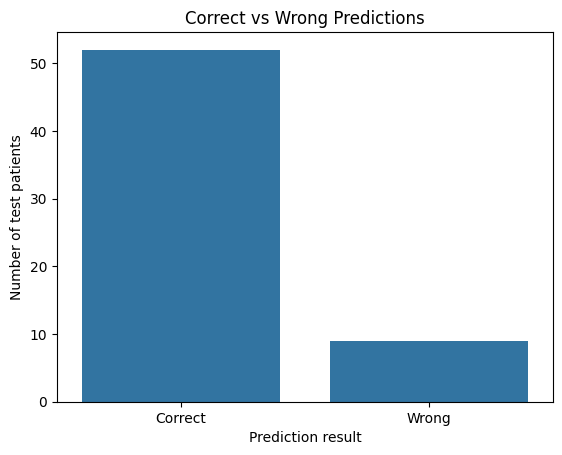

In [ ]:
sns.barplot(
    data=rf_prediction_summary,
    x="Prediction result",
    y="Number of test patients"
)
plt.title("Correct vs Wrong Predictions")
plt.xlabel("Prediction result")
plt.ylabel("Number of test patients")
plt.show()

Random Forest Model 2

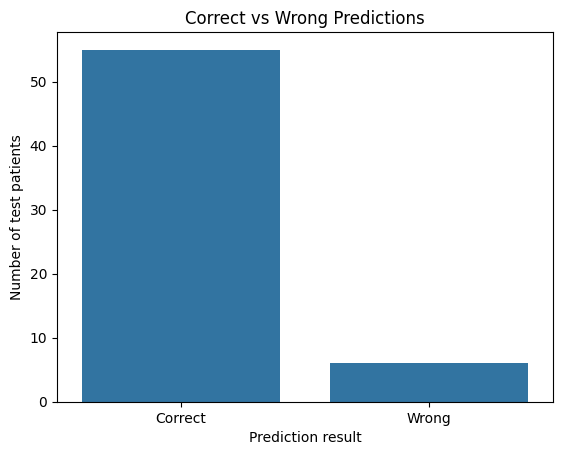

In [ ]:
sns.barplot(
    data=rf2_prediction_summary,
    x="Prediction result",
    y="Number of test patients"
)
plt.title("Correct vs Wrong Predictions")
plt.xlabel("Prediction result")
plt.ylabel("Number of test patients")
plt.show()

Logistic Regression Model

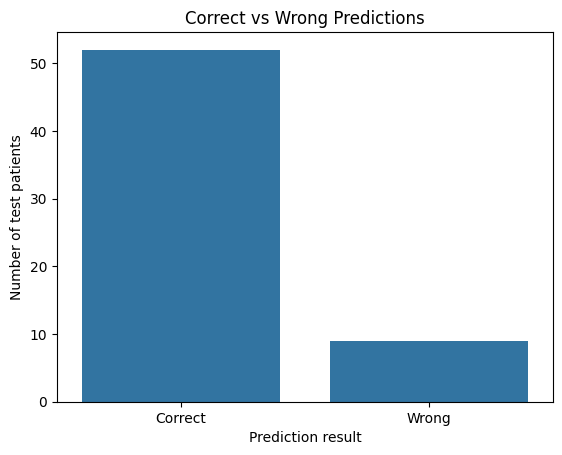

In [ ]:
sns.barplot(
    data=rf_prediction_summary,
    x="Prediction result",
    y="Number of test patients"
)
plt.title("Correct vs Wrong Predictions")
plt.xlabel("Prediction result")
plt.ylabel("Number of test patients")
plt.show()

##Inspect the wrong predictions only for All Models

Random Forest Model 1

In [ ]:
rf_wrong_predictions = rf_prediction_results[
    rf_prediction_results["Prediction_result"] == "Wrong"
]

print("Number of wrong predictions:", rf_wrong_predictions.shape[0])

if rf_wrong_predictions.shape[0] == 0:
    print("The model made no wrong predictions in this test set.")
    print("This can happen when the classes are easy to separate or the test set is small.")
    print("In harder datasets, such as Heart Disease, wrong predictions are more likely and must be discussed carefully.")
else:
    display(rf_wrong_predictions[_rf_columns_to_show])

Number of wrong predictions: 9


,age,sex,trestbps,chol,fbs,exang,oldpeak,ca,restecg_1.0,restecg_2.0,...,thal_4.73421926910299,thal_6.0,thal_7.0,Actual_y,Predicted_y,Actual_class,Predicted_class,Probability_Heart_Disease,Model_confidence,Prediction_result
17,69.0,1.0,160.0,234.0,1.0,0.0,0.1,1.000000,False,True,...,False,False,False,0,1,No Heart Disease,Has Heart Disease,0.538,0.538,Wrong
20,59.0,1.0,135.0,234.0,0.0,0.0,0.5,0.000000,False,False,...,False,False,True,0,1,No Heart Disease,Has Heart Disease,0.506,0.506,Wrong
24,55.0,0.0,180.0,327.0,0.0,1.0,3.4,0.000000,True,False,...,False,False,False,1,0,Has Heart Disease,No Heart Disease,0.499,0.501,Wrong
32,44.0,1.0,120.0,169.0,0.0,1.0,2.8,0.000000,False,False,...,False,True,False,1,0,Has Heart Disease,No Heart Disease,0.432,0.568,Wrong
33,58.0,1.0,125.0,220.0,0.0,0.0,0.4,0.672241,False,False,...,False,False,True,0,1,No Heart Disease,Has Heart Disease,0.635,0.635,Wrong
37,60.0,1.0,140.0,185.0,0.0,0.0,3.0,0.000000,False,True,...,False,False,False,1,0,Has Heart Disease,No Heart Disease,0.439,0.561,Wrong
40,62.0,1.0,130.0,231.0,0.0,0.0,1.8,3.000000,False,False,...,False,False,True,0,1,No Heart Disease,Has Heart Disease,0.714,0.714,Wrong
52,51.0,1.0,94.0,227.0,0.0,1.0,0.0,1.000000,False,False,...,False,False,True,0,1,No Heart Disease,Has Heart Disease,0.563,0.563,Wrong
54,59.0,0.0,174.0,249.0,0.0,1.0,0.0,0.000000,False,False,...,False,False,False,1,0,Has Heart Disease,No Heart Disease,0.410,0.590,Wrong


##Inspect the correct predictions only for All Models

Random Forest Model 1

In [ ]:
# Show a few examples where the model was correct

rf_correct_predictions = rf_prediction_results[
    rf_prediction_results["Prediction_result"] == "Correct"
]

print("Number of correct predictions:", rf_correct_predictions.shape[0])
rf_correct_predictions[_rf_columns_to_show].head(10)

Number of correct predictions: 52


,age,sex,trestbps,chol,fbs,exang,oldpeak,ca,restecg_1.0,restecg_2.0,...,thal_4.73421926910299,thal_6.0,thal_7.0,Actual_y,Predicted_y,Actual_class,Predicted_class,Probability_Heart_Disease,Model_confidence,Prediction_result
0,59.0,1.0,138.0,271.0,0.0,0.0,0.0,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.323,0.677,Correct
1,66.0,1.0,160.0,228.0,0.0,0.0,2.3,0.0,False,True,...,False,True,False,0,0,No Heart Disease,No Heart Disease,0.405,0.595,Correct
2,51.0,0.0,130.0,256.0,0.0,0.0,0.5,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.215,0.785,Correct
3,34.0,1.0,118.0,182.0,0.0,0.0,0.0,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.254,0.746,Correct
4,54.0,1.0,150.0,232.0,0.0,0.0,1.6,0.0,False,True,...,False,False,True,0,0,No Heart Disease,No Heart Disease,0.499,0.501,Correct
5,60.0,0.0,120.0,178.0,1.0,0.0,0.0,0.0,False,False,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.236,0.764,Correct
6,63.0,0.0,140.0,195.0,0.0,0.0,0.0,2.0,False,False,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.385,0.615,Correct
7,74.0,0.0,120.0,269.0,0.0,1.0,0.2,1.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.466,0.534,Correct
8,35.0,1.0,126.0,282.0,0.0,1.0,0.0,0.0,False,True,...,False,False,True,1,1,Has Heart Disease,Has Heart Disease,0.524,0.524,Correct
9,45.0,0.0,138.0,236.0,0.0,1.0,0.2,0.0,False,True,...,False,False,False,0,0,No Heart Disease,No Heart Disease,0.369,0.631,Correct


##Confusion matrix for the Random Forest Model

Random Forest Model 1

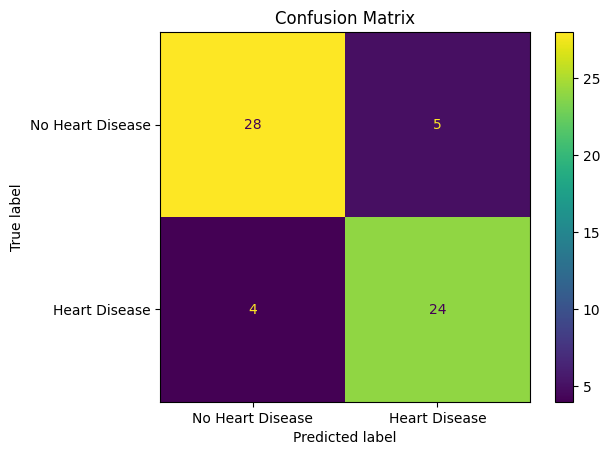

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

Random Forest Model 2

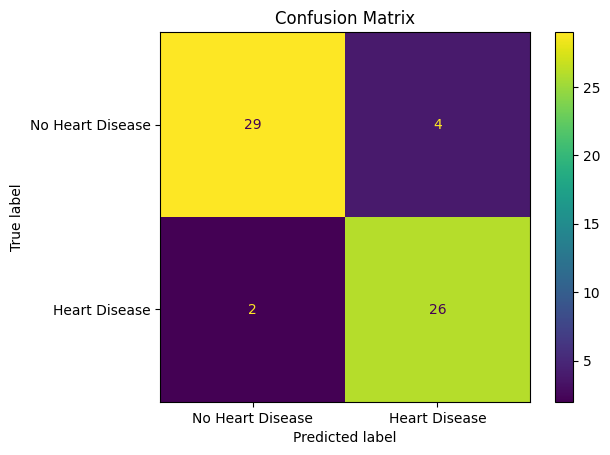

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test_hr,
    rf2_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

Random Forest Model 3

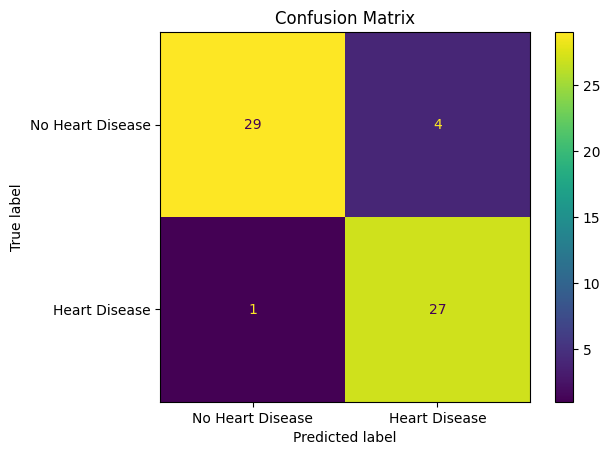

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test_chest_bp,
    rf3_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

Random Forest Model 4

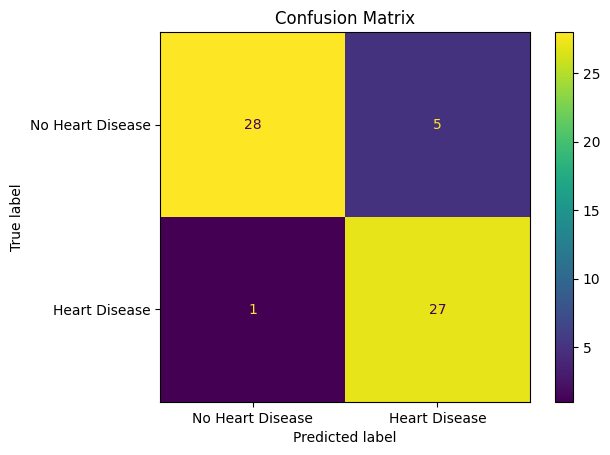

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test_thalach_bp,
    rf4_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

Logistic Regression Model

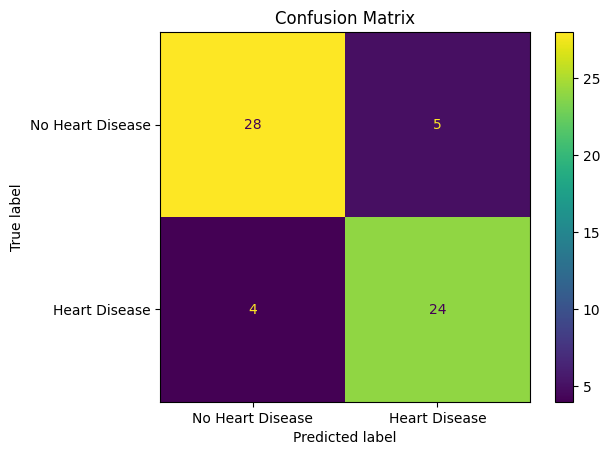

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

Logistic Regression Model 2

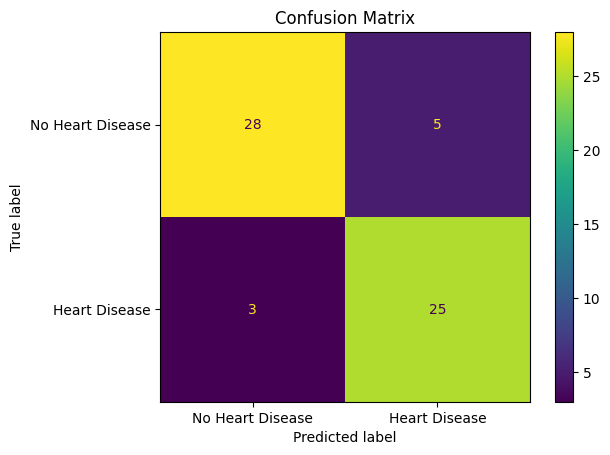

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test_hr,
    lr2_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

Logistic Regression Model 3

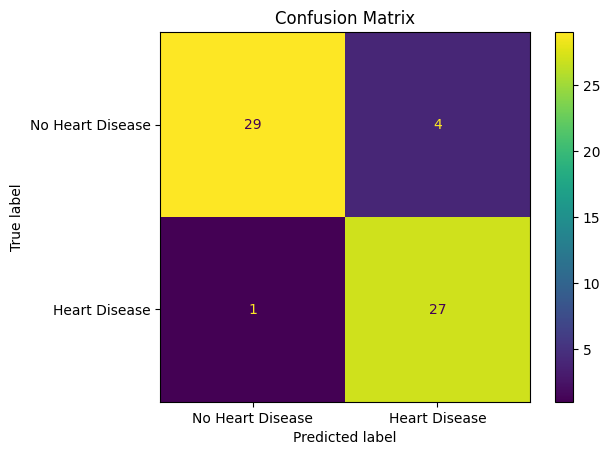

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test_chest_bp,
    lr3_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

Logistic Regression Model 4

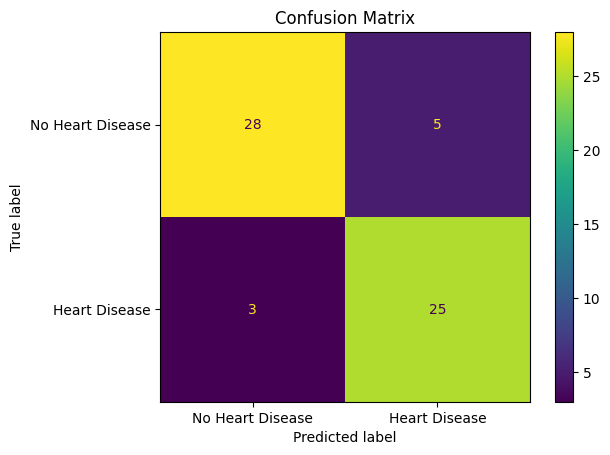

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test_thalach_bp,
    lr4_pred,
    display_labels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix")
plt.show()

##Area under the curve graphs

Random Forest Model 1

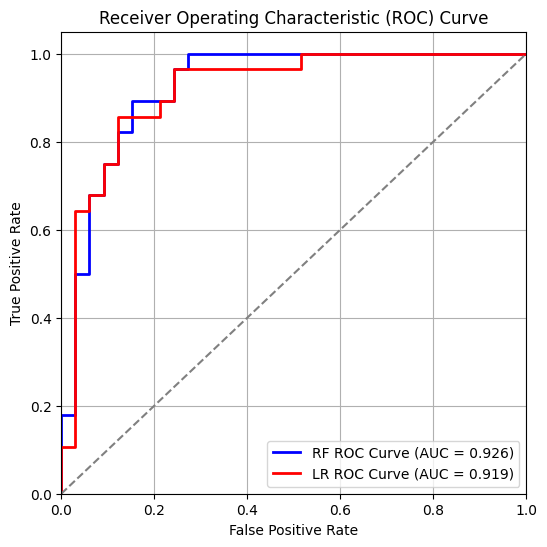

In [ ]:
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
from sklearn.metrics import roc_curve, auc

fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, y_prob_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

plt.figure(figsize=(6,6))
plt.plot(fpr_rf, tpr_rf, color='blue', lw=2,
         label=f'RF ROC Curve (AUC = {roc_auc_rf:.3f})')
plt.plot(fpr_lr, tpr_lr, color='red', lw=2,
         label=f'LR ROC Curve (AUC = {roc_auc_lr:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

Random Forest Model 2

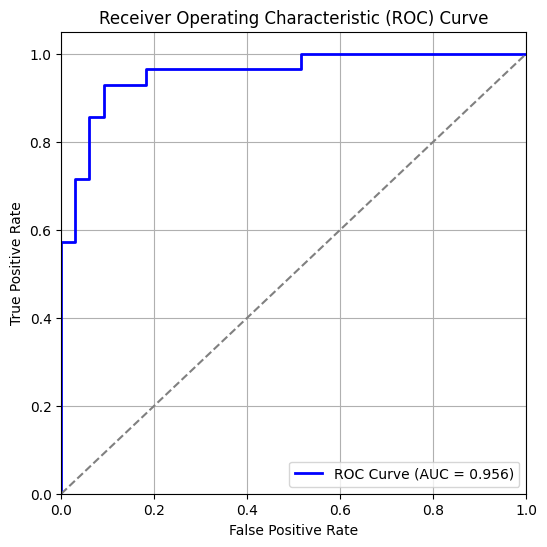

In [ ]:
y_prob_rf2 = rf2_model.predict_proba(X_test_hr)[:, 1]
from sklearn.metrics import roc_curve, auc

fpr_rf2, tpr_rf2, thresholds_rf2 = roc_curve(y_test_hr, y_prob_rf2)
roc_auc_rf2 = auc(fpr_rf2, tpr_rf2)
plt.figure(figsize=(6,6))
plt.plot(fpr_rf2, tpr_rf2, color='blue', lw=2,
         label=f'ROC Curve (AUC = {roc_auc_rf2:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

Random Forest Model 3

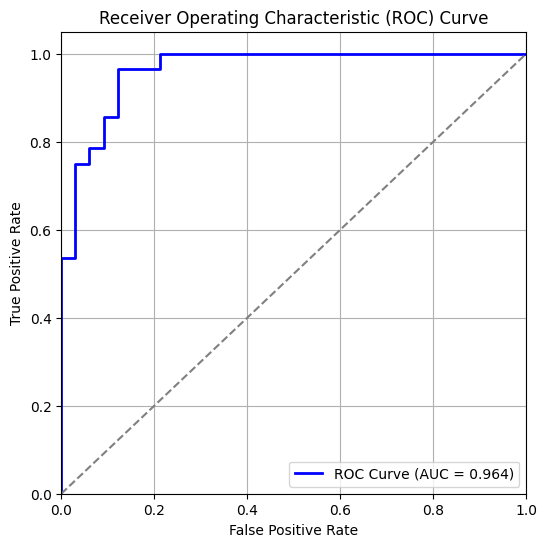

In [ ]:
y_prob_rf3 = rf3_model.predict_proba(X_test_chest_bp)[:, 1]
from sklearn.metrics import roc_curve, auc

fpr_rf3, tpr_rf3, thresholds_rf3 = roc_curve(y_test_chest_bp, y_prob_rf3)
roc_auc_rf3 = auc(fpr_rf3, tpr_rf3)
plt.figure(figsize=(6,6))
plt.plot(fpr_rf3, tpr_rf3, color='blue', lw=2,
         label=f'ROC Curve (AUC = {roc_auc_rf3:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

Logistic Regression Model

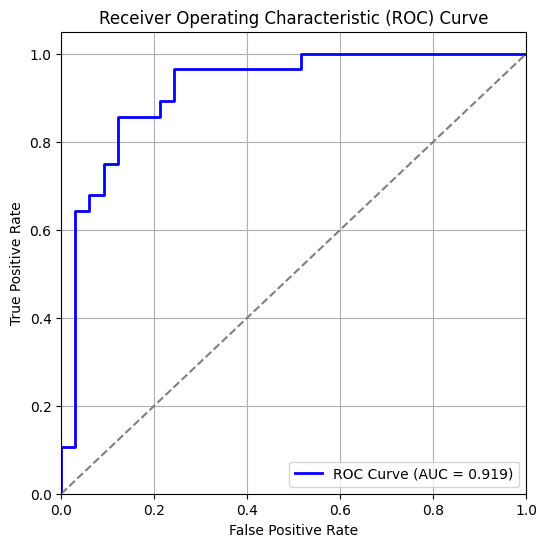

In [ ]:
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
from sklearn.metrics import roc_curve, auc

fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, y_prob_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)
plt.figure(figsize=(6,6))
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2,
         label=f'ROC Curve (AUC = {roc_auc_lr:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

Logistic Regression Model 2

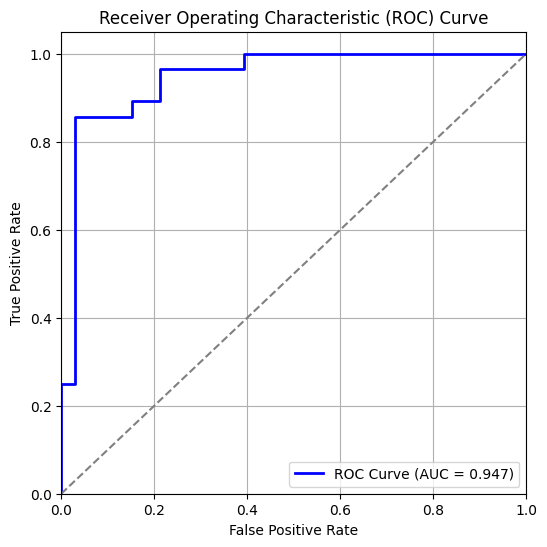

In [ ]:
y_prob_lr2 = lr2_model.predict_proba(X_test_hr)[:, 1]
from sklearn.metrics import roc_curve, auc

fpr_lr2, tpr_lr2, thresholds_lr2 = roc_curve(y_test_hr, y_prob_lr2)
roc_auc_lr2 = auc(fpr_lr2, tpr_lr2)
plt.figure(figsize=(6,6))
plt.plot(fpr_lr2, tpr_lr2, color='blue', lw=2,
         label=f'ROC Curve (AUC = {roc_auc_lr2:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

Random Forest Model 1 and Logistic Regression Model 3 (Best Models)

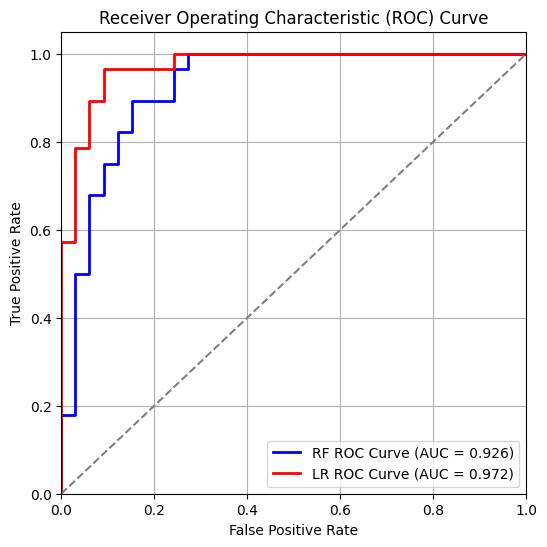

In [ ]:
y_prob_lr3 = lr3_model.predict_proba(X_test_chest_bp)[:, 1]
fpr_lr3, tpr_lr3, thresholds_lr3 = roc_curve(y_test_chest_bp, y_prob_lr3)
roc_auc_lr3 = auc(fpr_lr3, tpr_lr3)

plt.figure(figsize=(6,6))
plt.plot(fpr_rf, tpr_rf, color='blue', lw=2,
         label=f'RF ROC Curve (AUC = {roc_auc_rf:.3f})')
plt.plot(fpr_lr3, tpr_lr3, color='red', lw=2,
         label=f'LR ROC Curve (AUC = {roc_auc_lr3:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

##Explain the Model with SHAP



Random Forest Model 1

In [ ]:
explainer = shap.TreeExplainer(rf_model)
explanation = explainer(X_test)


rf_positive_class_index = 1

if explanation.values.ndim == 3:
    rf_shap_heart = explanation[:, :, rf_positive_class_index]
else:
    rf_shap_heart = explanation

print("SHAP values calculated for the test set.")


SHAP values calculated for the test set.


Random Forest Model 2

In [ ]:
explainer_rf2 = shap.TreeExplainer(rf2_model)
explanation_rf2 = explainer_rf2(X_test_hr)


rf2_positive_class_index = 1

if explanation_rf2.values.ndim == 3:
    rf2_shap_heart = explanation_rf2[:, :, rf2_positive_class_index]
else:
    rf2_shap_heart = explanation_rf2

print("SHAP values calculated for the test set.")


SHAP values calculated for the test set.


Random Forest Model 3

In [ ]:
import shap
explainer_rf3 = shap.TreeExplainer(rf3_model)
explanation_rf3 = explainer_rf3(X_test_chest_bp)


rf3_positive_class_index = 1

if explanation_rf3.values.ndim == 3:
    rf3_shap_heart = explanation_rf3[:, :, rf3_positive_class_index]
else:
    rf3_shap_heart = explanation_rf3

print("SHAP values calculated for the test set.")

SHAP values calculated for the test set.


Logistic Regression Model

In [ ]:
X_train_numeric = X_train.copy()
X_test_numeric = X_test.copy()

for col in X_train_numeric.select_dtypes(include='bool').columns:
    X_train_numeric[col] = X_train_numeric[col].astype(int)
    X_test_numeric[col] = X_test_numeric[col].astype(int)

# Create SHAP explainer for Logistic Regression
explainer_lr = shap.LinearExplainer(
    lr_model,
    X_train_numeric,
    feature_perturbation="interventional"
)

# Calculate SHAP values
explanation_lr = explainer_lr(X_test_numeric)

# Keep the SHAP Explanation object for plotting
lr_shap_heart = explanation_lr

print("SHAP values calculated for the test set.")

SHAP values calculated for the test set.


Logistic Regression Model 2

In [ ]:
X_train_hr_numeric = X_train_hr.copy()
X_test_hr_numeric = X_test_hr.copy()

for col in X_train_hr_numeric.select_dtypes(include='bool').columns:
    X_train_hr_numeric[col] = X_train_hr_numeric[col].astype(int)
    X_test_hr_numeric[col] = X_test_hr_numeric[col].astype(int)

# Create SHAP explainer for Logistic Regression
explainer_lr2 = shap.LinearExplainer(
    lr2_model,
    X_train_hr_numeric,
    feature_perturbation="interventional"
)

# Calculate SHAP values
explanation_lr2 = explainer_lr2(X_test_hr_numeric)

# Keep the SHAP Explanation object for plotting
lr2_shap_heart = explanation_lr2

print("SHAP values calculated for the test set.")

SHAP values calculated for the test set.


Logistic Regression Model 3

In [ ]:
X_train_chest_bp_numeric = X_train_chest_bp.copy()
X_test_chest_bp_numeric = X_test_chest_bp.copy()

for col in X_train_chest_bp_numeric.select_dtypes(include='bool').columns:
    X_train_chest_bp_numeric[col] = X_train_chest_bp_numeric[col].astype(int)
    X_test_chest_bp_numeric[col] = X_test_chest_bp_numeric[col].astype(int)

# Create SHAP explainer for Logistic Regression
explainer_lr3 = shap.LinearExplainer(
    lr3_model,
    X_train_chest_bp_numeric,
    feature_perturbation="interventional"
)

# Calculate SHAP values
explanation_lr3 = explainer_lr3(X_test_chest_bp_numeric)

# Keep the SHAP Explanation object for plotting
lr3_shap_heart = explanation_lr3

print("SHAP values calculated for the test set.")

SHAP values calculated for the test set.


Logistic Regression Model 4

In [ ]:
X_train_thalach_bp_numeric = X_train_thalach_bp.copy()
X_test_thalach_bp_numeric = X_test_thalach_bp.copy()

for col in X_train_thalach_bp_numeric.select_dtypes(include='bool').columns:
    X_train_thalach_bp_numeric[col] = X_train_thalach_bp_numeric[col].astype(int)
    X_test_thalach_bp_numeric[col] = X_test_thalach_bp_numeric[col].astype(int)

# Create SHAP explainer for Logistic Regression
explainer_lr4 = shap.LinearExplainer(
    lr4_model,
    X_train_thalach_bp_numeric,
    feature_perturbation="interventional"
)

# Calculate SHAP values
explanation_lr4 = explainer_lr4(X_test_thalach_bp_numeric)

# Keep the SHAP Explanation object for plotting
lr4_shap_heart = explanation_lr4

print("SHAP values calculated for the test set.")

SHAP values calculated for the test set.


##SHAP Global Feature Importance for All Models

Random Forest Model 1

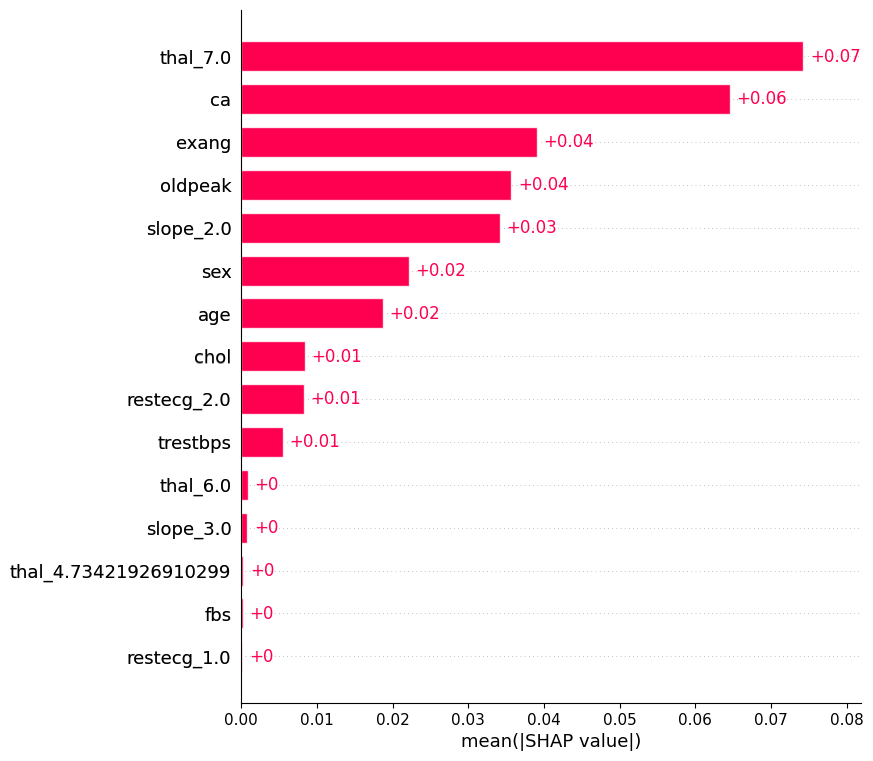

In [ ]:
shap.plots.bar(rf_shap_heart, max_display=20)

Random Forest Model 2

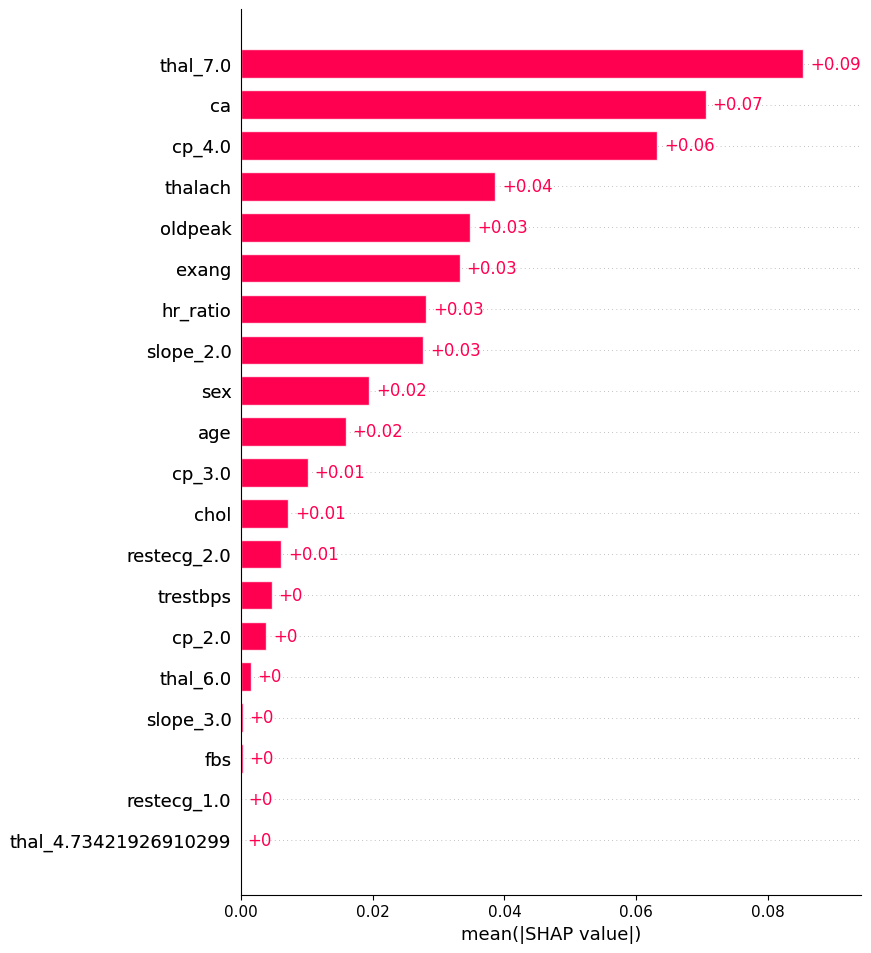

In [ ]:
shap.plots.bar(rf2_shap_heart, max_display=20)

Random Forest Model 3

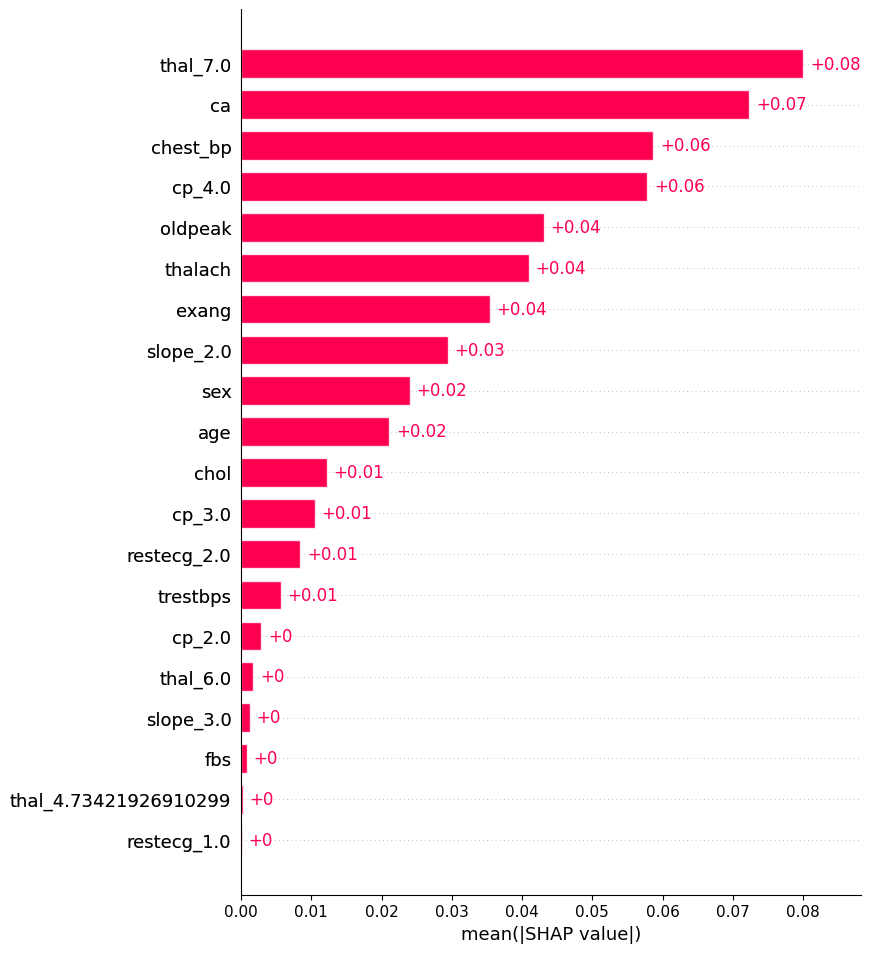

In [ ]:
shap.plots.bar(rf3_shap_heart, max_display=20)

Logistic Regression Model

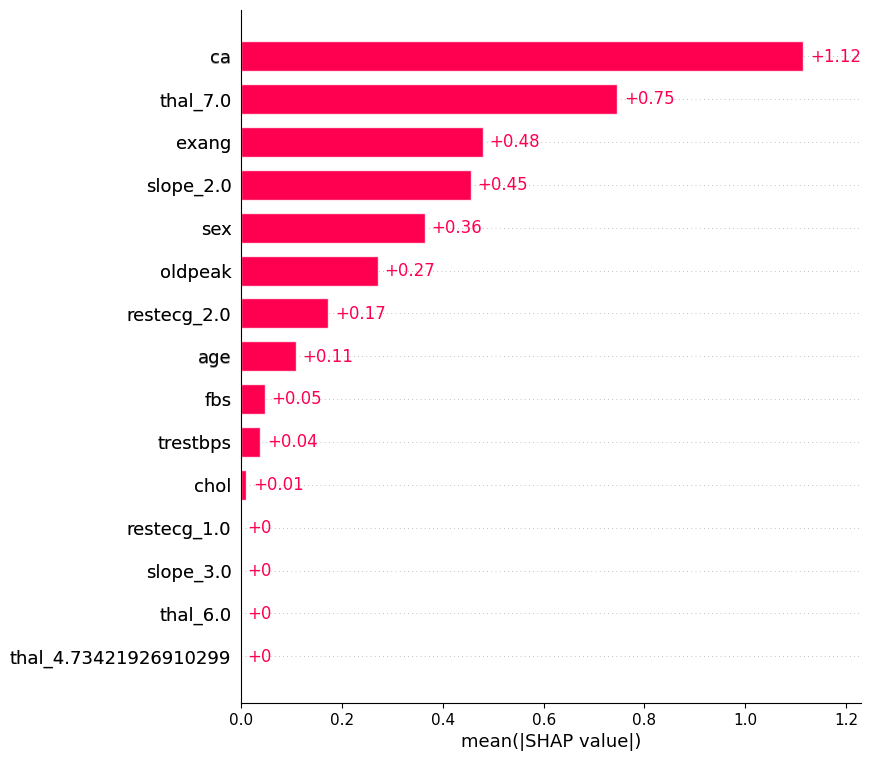

In [ ]:
shap.plots.bar(lr_shap_heart, max_display=20)

Logistic Regression Model 2

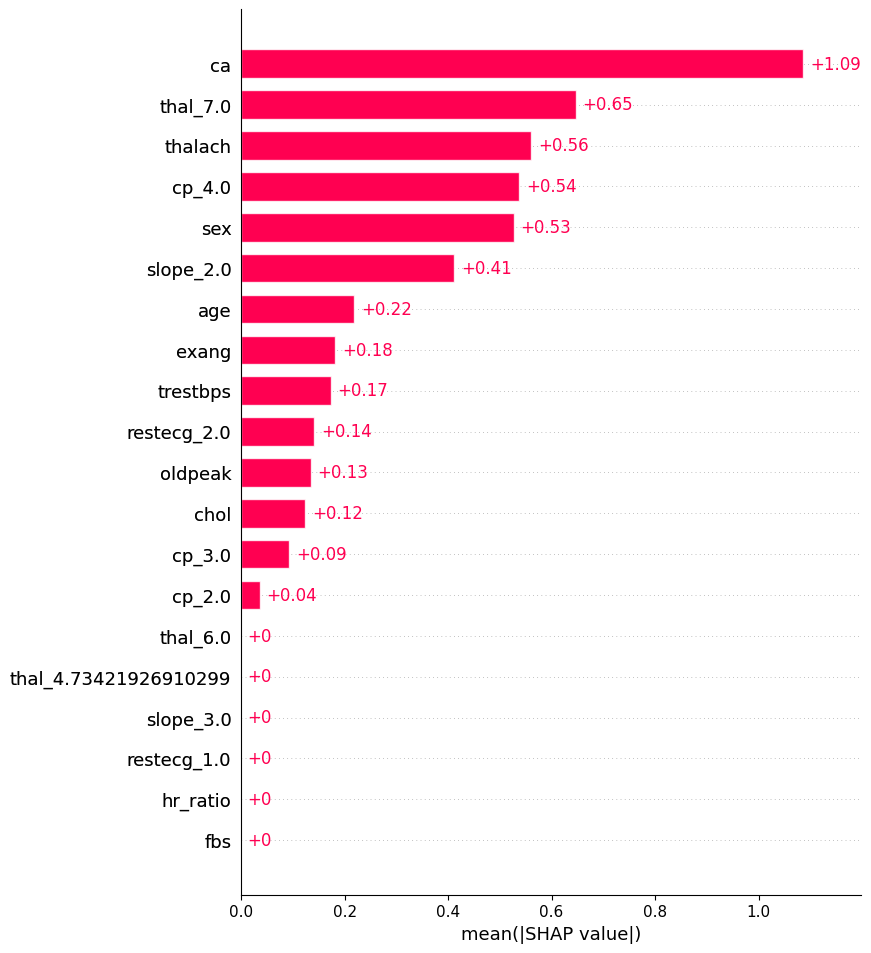

In [ ]:
shap.plots.bar(lr2_shap_heart, max_display=20)

Logistic Regression Model 3

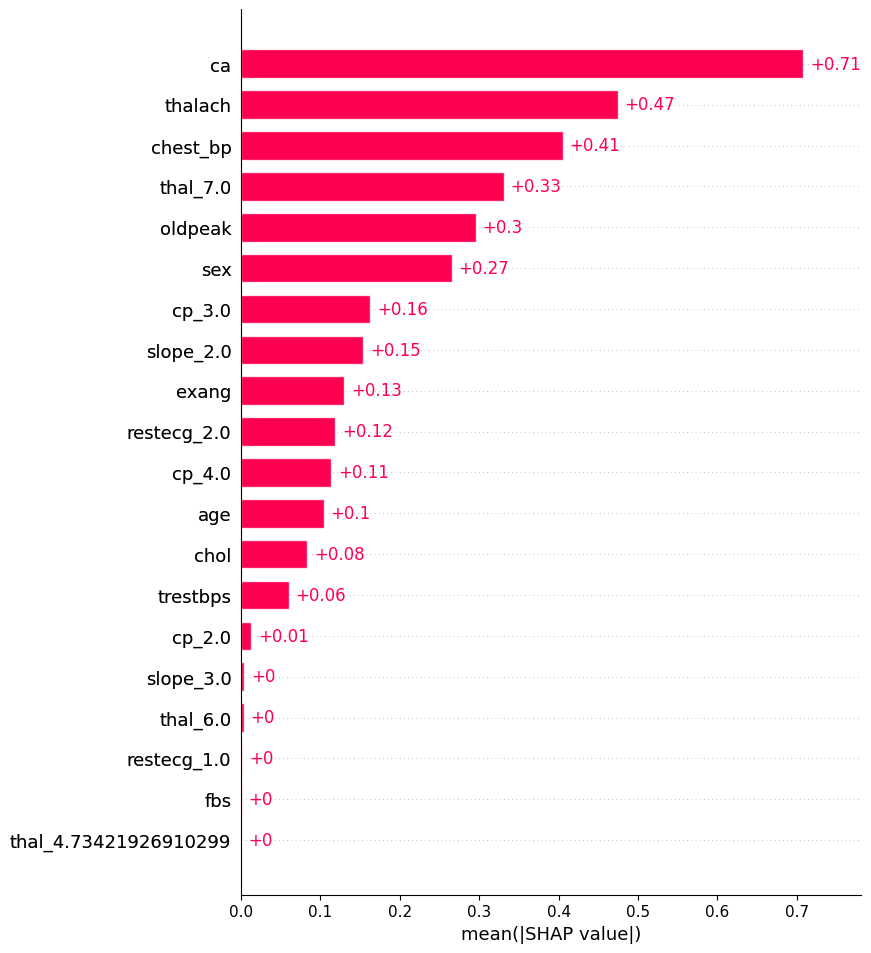

In [ ]:
shap.plots.bar(lr3_shap_heart, max_display=20)

Logistic Regression Model 4

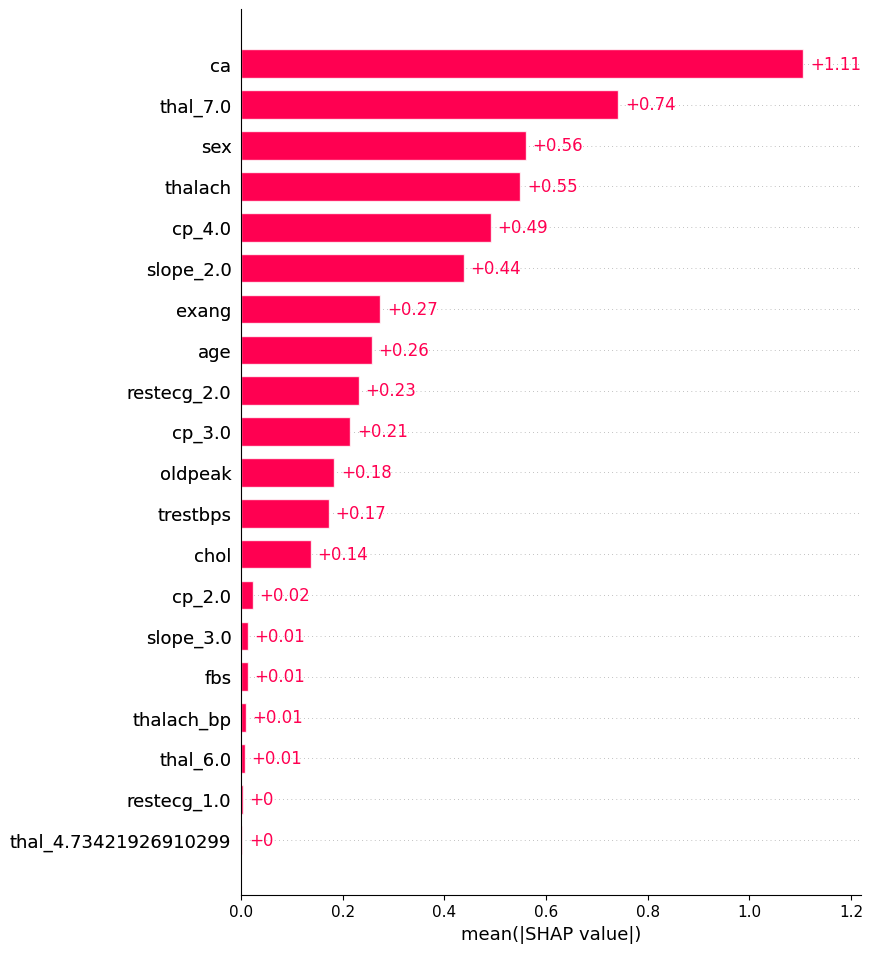

In [ ]:
shap.plots.bar(lr4_shap_heart, max_display=20)

##SHAP Beeswarm Plot for All Models

Random Forest Model 1

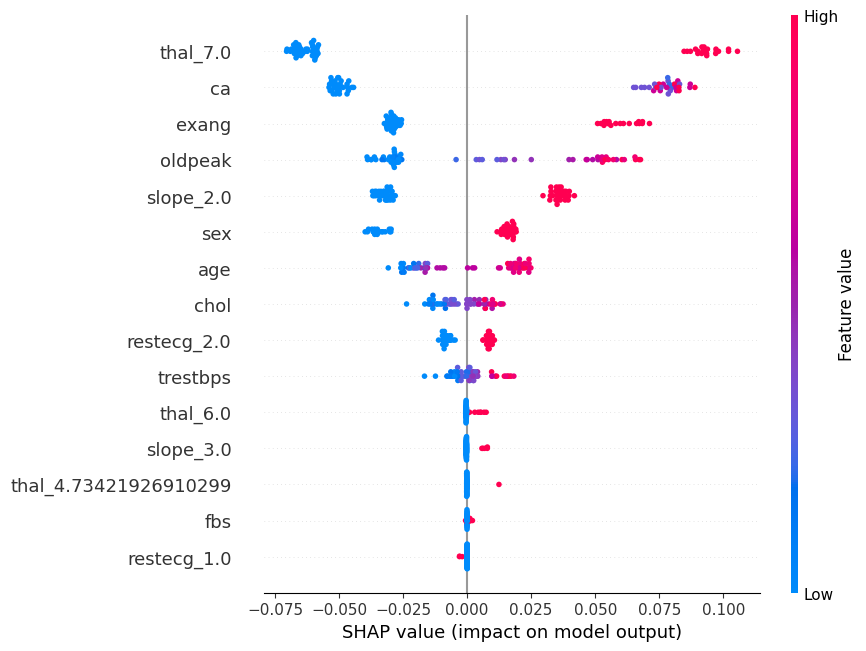

In [ ]:

shap.plots.beeswarm(rf_shap_heart, max_display=20)

Random Forest Model 2

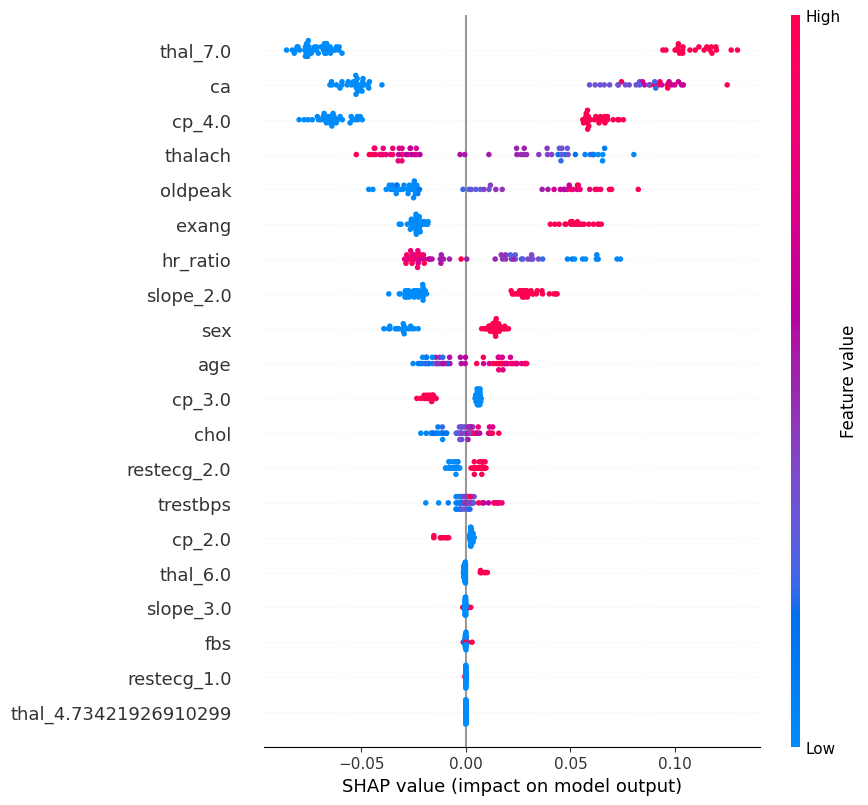

In [ ]:
shap.plots.beeswarm(rf2_shap_heart, max_display=20)

Logistic Regression Model 1

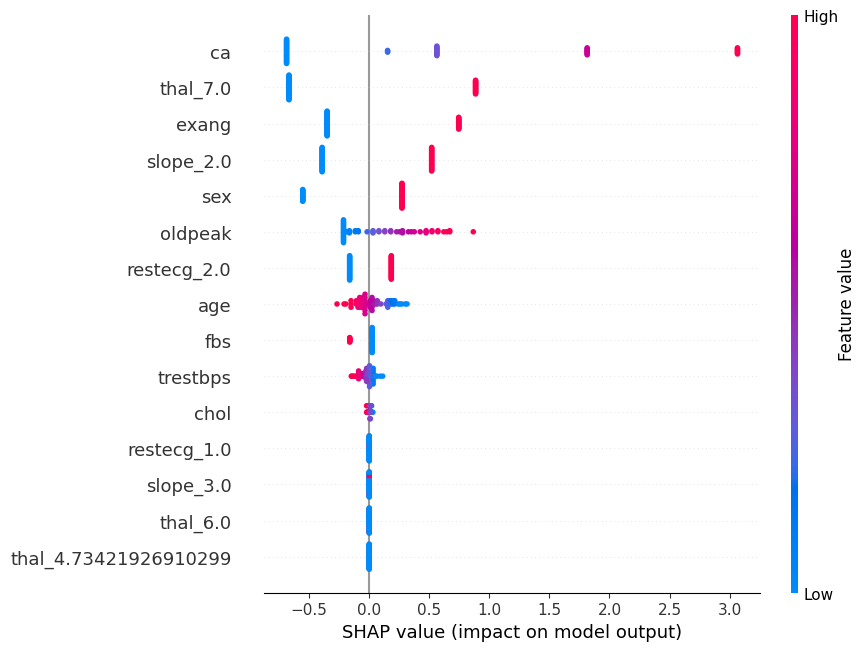

In [ ]:
shap.plots.beeswarm(lr_shap_heart, max_display=20)

Logistic Regression Model 2

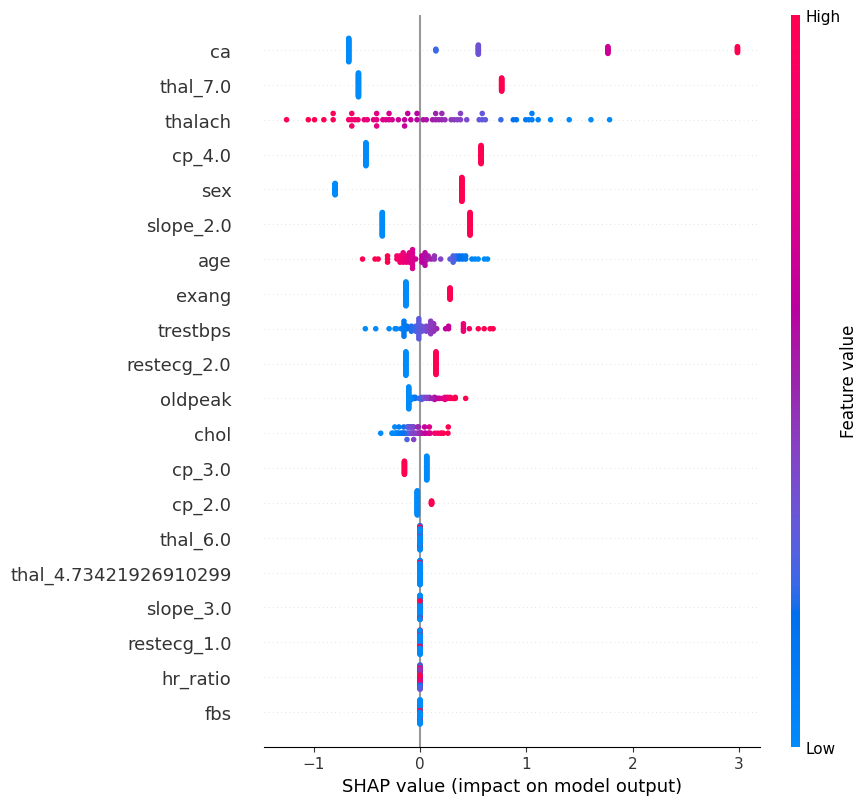

In [ ]:
shap.plots.beeswarm(lr2_shap_heart, max_display=20)

Logistic Regression Model 3

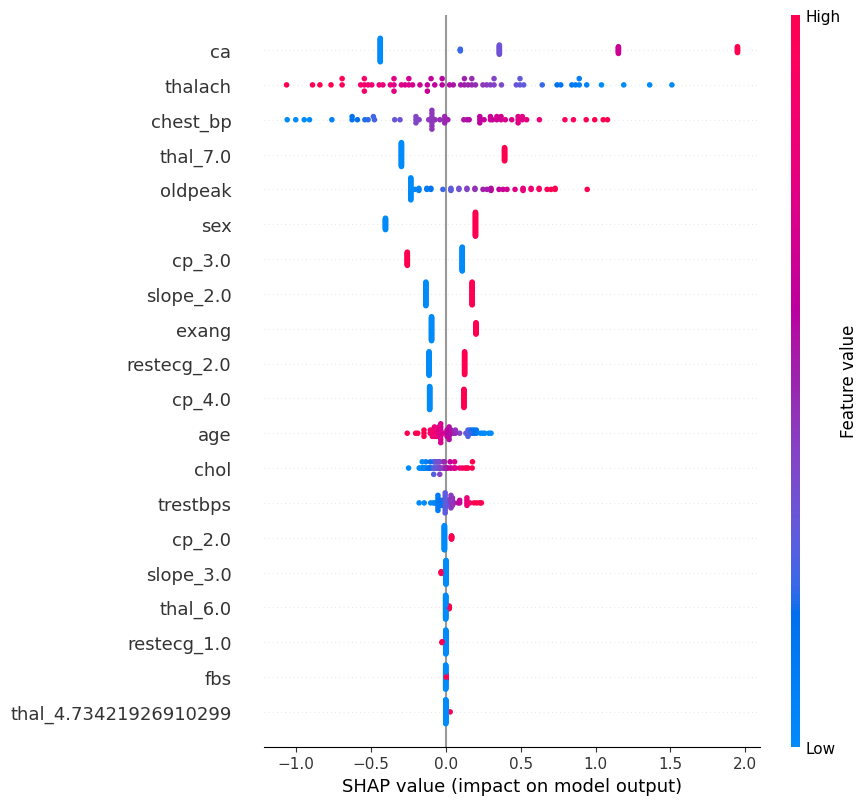

In [ ]:
shap.plots.beeswarm(lr3_shap_heart, max_display=20)

##SHAP Local Explanation, One Prediction for All Models

Random Forest Model 1

In [ ]:
i = 5

rf_actual_label = "Heart Disease" if y_test.iloc[i] == 1 else "No Heart Disease"
rf_predicted_label = "Heart Disease" if rf_pred[i] == 1 else "No Heart Disease"
prob_heart = rf_model.predict_proba(X_test.iloc[[i]])[0][1]

print("Example number:", i)
print("Actual class:", rf_actual_label)
print("Predicted class:", rf_predicted_label)
print("Model probability of Heart Disease:", round(prob_heart, 3))


Example number: 5
Actual class: No Heart Disease
Predicted class: No Heart Disease
Model probability of Heart Disease: 0.236


Random Forest Model 2

In [ ]:
i = 5

rf2_actual_label = "Heart Disease" if y_test_hr.iloc[i] == 1 else "No Heart Disease"
rf2_predicted_label = "Heart Disease" if rf2_pred[i] == 1 else "No Heart Disease"
prob_heart_rf2 = rf2_model.predict_proba(X_test_hr.iloc[[i]])[0][1]

print("Example number:", i)
print("Actual class:", rf2_actual_label)
print("Predicted class:", rf2_predicted_label)
print("Model probability of Heart Disease:", round(prob_heart_rf2, 3))


Example number: 5
Actual class: No Heart Disease
Predicted class: No Heart Disease
Model probability of Heart Disease: 0.338


Logistic Regression Model

In [ ]:
i = 5

lr_actual_label = "Heart Disease" if y_test.iloc[i] == 1 else "No Heart Disease"
lr_predicted_label = "Heart Disease" if lr_pred[i] == 1 else "No Heart Disease"
prob_heart_lr = lr_model.predict_proba(X_test.iloc[[i]])[0][1]

print("Example number:", i)
print("Actual class:", lr_actual_label)
print("Predicted class:", lr_predicted_label)
print("Model probability of Heart Disease:", round(prob_heart_lr, 3))


Example number: 5
Actual class: No Heart Disease
Predicted class: No Heart Disease
Model probability of Heart Disease: 0.032


Logistic Regression Model 2

In [ ]:
i = 5

lr2_actual_label = "Heart Disease" if y_test_hr.iloc[i] == 1 else "No Heart Disease"
lr2_predicted_label = "Heart Disease" if lr2_pred[i] == 1 else "No Heart Disease"
prob_heart_lr2 = lr2_model.predict_proba(X_test_hr.iloc[[i]])[0][1]

print("Example number:", i)
print("Actual class:", lr2_actual_label)
print("Predicted class:", lr2_predicted_label)
print("Model probability of Heart Disease:", round(prob_heart_lr2, 3))


Example number: 5
Actual class: No Heart Disease
Predicted class: No Heart Disease
Model probability of Heart Disease: 0.071


Logistic Regression Model 3

In [ ]:
i = 5

lr3_actual_label = "Heart Disease" if y_test_chest_bp.iloc[i] == 1 else "No Heart Disease"
lr3_predicted_label = "Heart Disease" if lr3_pred[i] == 1 else "No Heart Disease"
prob_heart_lr3 = lr3_model.predict_proba(X_test_chest_bp.iloc[[i]])[0][1]

print("Example number:", i)
print("Actual class:", lr3_actual_label)
print("Predicted class:", lr3_predicted_label)
print("Model probability of Heart Disease:", round(prob_heart_lr3, 3))


Example number: 5
Actual class: No Heart Disease
Predicted class: No Heart Disease
Model probability of Heart Disease: 0.204


# SHAP waterfall plot for one individual prediction


Random Forest Model 1

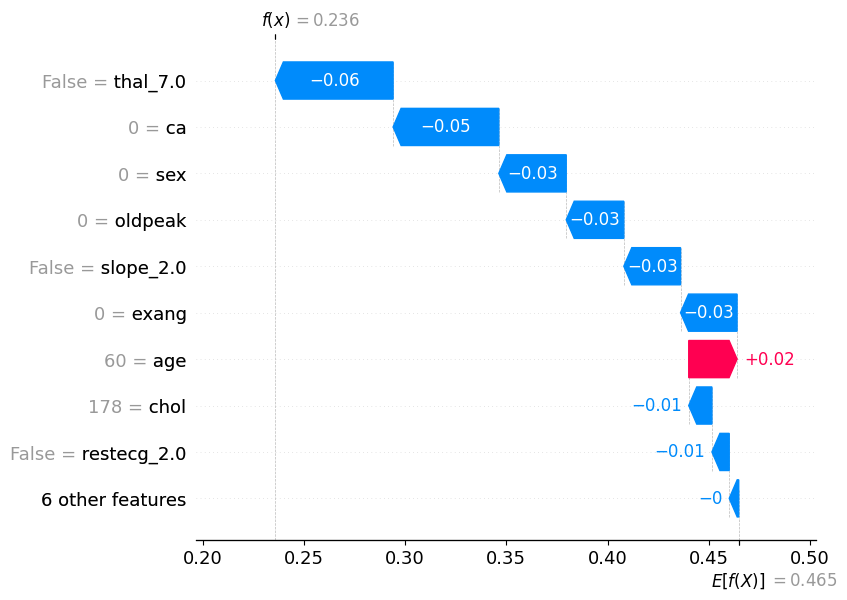

In [ ]:
shap.plots.waterfall(rf_shap_heart[i])


Random Forest Model 2

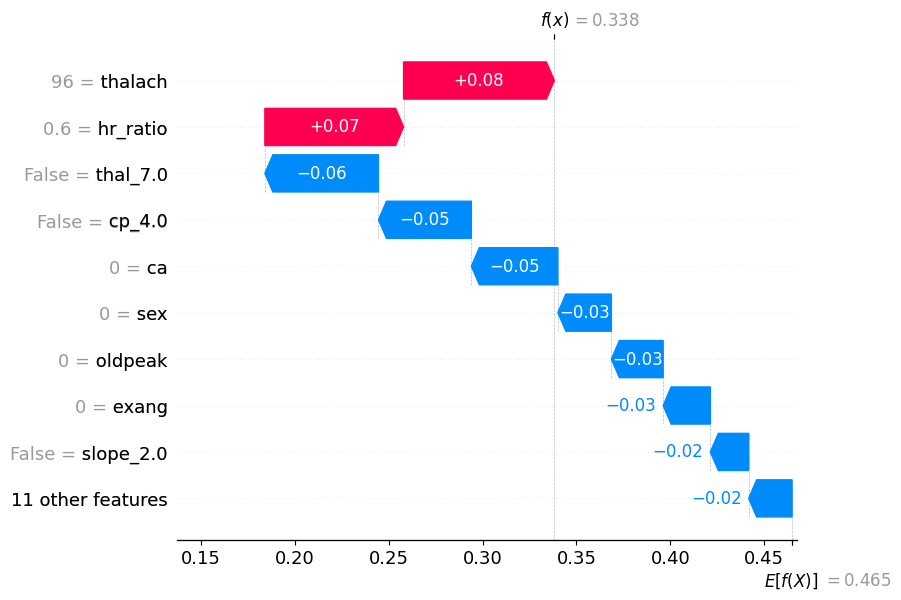

In [ ]:
shap.plots.waterfall(rf2_shap_heart[i])


Logistic Regression Model

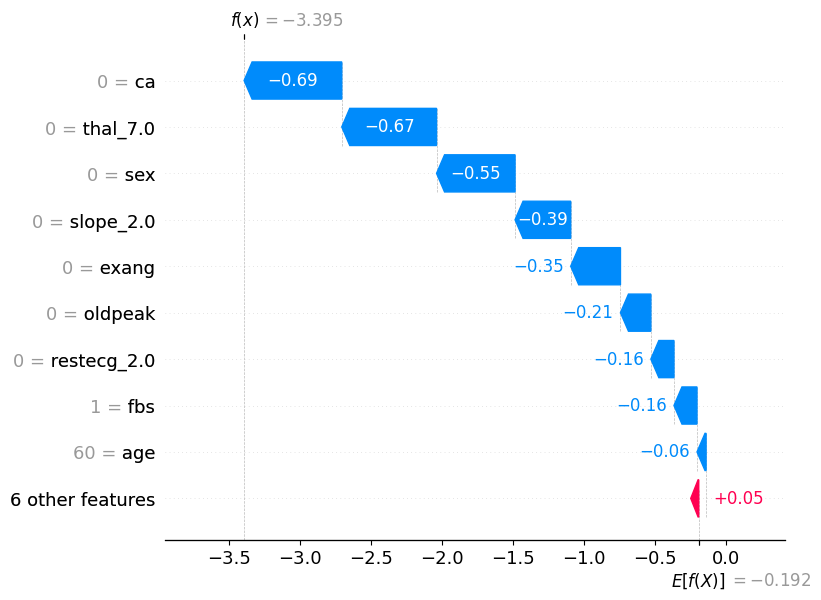

In [ ]:
shap.plots.waterfall(lr_shap_heart[i])

Logistic Regression Model 2

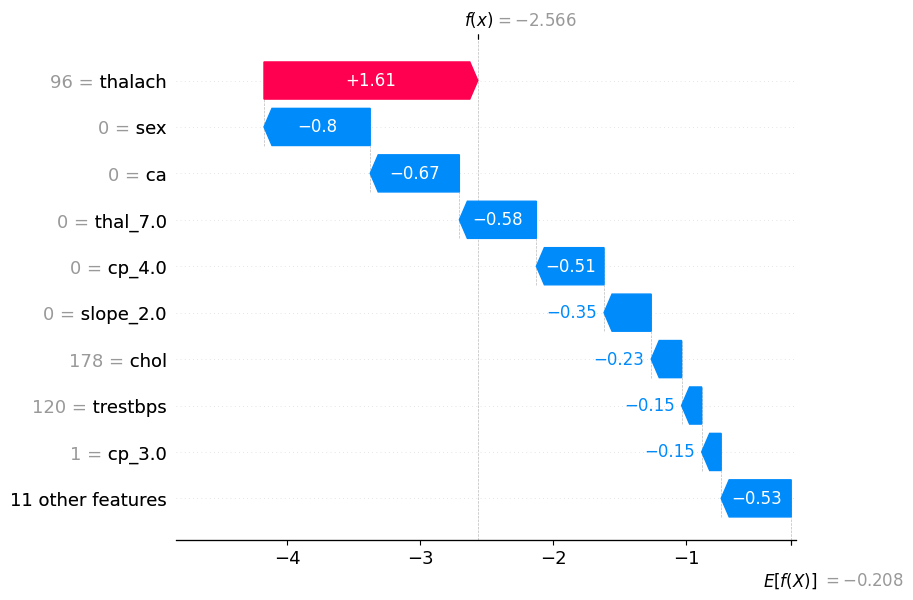

In [ ]:
shap.plots.waterfall(lr2_shap_heart[i])

Logistic Regression Model 3

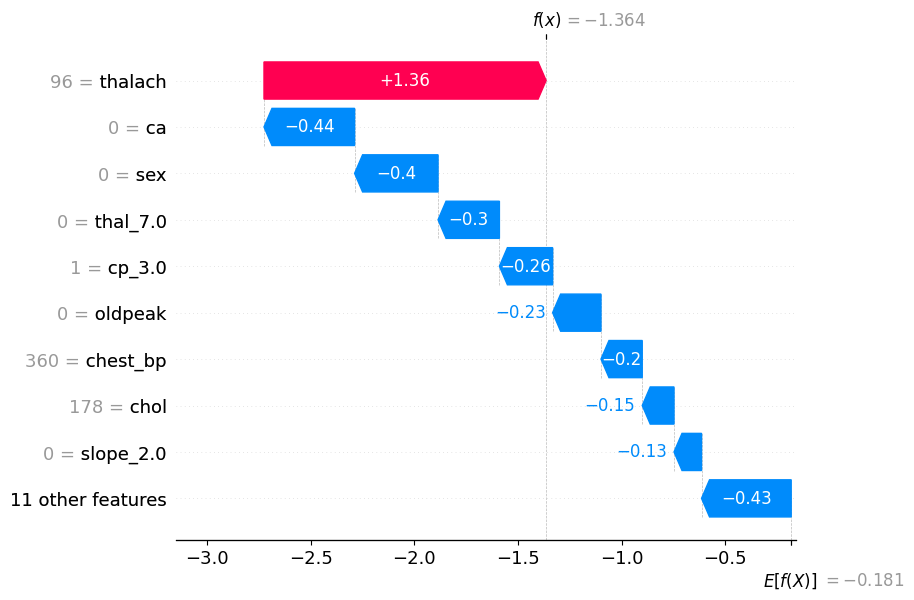

In [ ]:
shap.plots.waterfall(lr3_shap_heart[i])

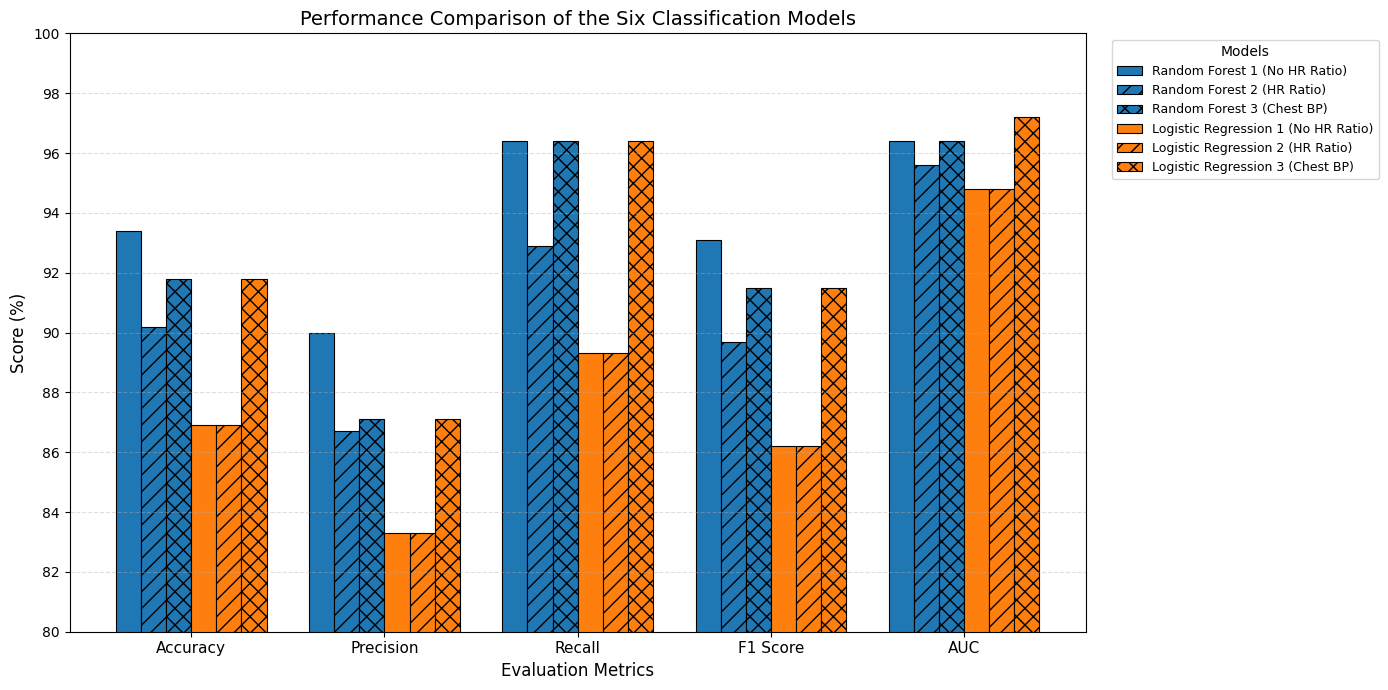

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics on the x-axis
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "AUC"]
x = np.arange(len(metrics))

# Results for all six models
results = {
    "Random Forest 1 (No HR Ratio)": [93.4, 90.0, 96.4, 93.1, 96.4],
    "Random Forest 2 (HR Ratio)": [90.2, 86.7, 92.9, 89.7, 95.6],
    "Random Forest 3 (Chest BP)": [91.8, 87.1, 96.4, 91.5, 96.4],

    "Logistic Regression 1 (No HR Ratio)": [86.9, 83.3, 89.3, 86.2, 94.8],
    "Logistic Regression 2 (HR Ratio)": [86.9, 83.3, 89.3, 86.2, 94.8],
    "Logistic Regression 3 (Chest BP)": [91.8, 87.1, 96.4, 91.5, 97.2]
}

# Two colours only
colors = {
    "Random Forest": "tab:blue",
    "Logistic Regression": "tab:orange"
}

# Different hatch patterns for the feature configurations
hatches = {
    "No HR Ratio": "",
    "HR Ratio": "//",
    "Chest BP": "xx"
}

# Width of each bar
bar_width = 0.13

# Offsets for six models
offsets = np.array([-2.5, -1.5, -0.5, 0.5, 1.5, 2.5]) * bar_width

plt.figure(figsize=(14, 7))

for offset, (model_name, scores) in zip(offsets, results.items()):

    # Select model-family colour
    if "Random Forest" in model_name:
        color = colors["Random Forest"]
    else:
        color = colors["Logistic Regression"]

    # Select hatch pattern
    if "No HR Ratio" in model_name:
        hatch = hatches["No HR Ratio"]
    elif "HR Ratio" in model_name:
        hatch = hatches["HR Ratio"]
    else:
        hatch = hatches["Chest BP"]

    plt.bar(
        x + offset,
        scores,
        width=bar_width,
        color=color,
        edgecolor="black",
        linewidth=0.8,
        hatch=hatch,
        label=model_name
    )

plt.xticks(x, metrics, fontsize=11)
plt.yticks(np.arange(80, 101, 2))
plt.ylim(80, 100)

plt.xlabel("Evaluation Metrics", fontsize=12)
plt.ylabel("Score (%)", fontsize=12)
plt.title(
    "Performance Comparison of the Six Classification Models",
    fontsize=14
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.legend(
    title="Models",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()